# Milestone 4: Final Model Pipeline &mdash; Housing Mention Detection in SMI Discharge Notes

**Project #63**

**Group Members:** Matlin Gilman and Brianna Grissom

## Overview

In this notebook we build out the **full final model pipeline** for detecting housing mentions in MIMIC-IV discharge notes for our Serious Mental Illness (SMI) cohort. We compare four detection methods end-to-end:

1. **Keyword search** &mdash; an expanded version of the Milestone 2 regex (28 patterns).
2. **TF-IDF + Random Forest** &mdash; the lexical baseline from Milestone 3.
3. **Word2Vec + MLP** &mdash; the embedding-based baseline from Milestone 3 (with F1-tuned threshold).
4. **Fine-tuned Bio_ClinicalBERT** &mdash; the contextual transformer from the Milestone 3 pipeline plan.

For each method we measure note-level housing-mention rates on the 3,808-admission SMI cohort, break those rates down by demographic subgroup (race, primary diagnosis, insurance, gender), and inspect a sample of the sentences that each model flags. The keyword search is also separately evaluated on the labeled MIMIC-III SDOH dataset to establish a precision/recall floor before we move to learned classifiers.

Sentence-level preprocessing follows the stricter narrative-prose filter we developed in Milestone 3 &mdash; section-aware splitting plus a stopword/comma/abbreviation density check. ClinicalBERT predictions on the SMI cohort are cached to Google Drive so that re-running this notebook does not require re-doing the ~3 hour inference pass.

## 1. Setup &amp; Imports

Standard data-handling and ML libraries plus the Hugging Face stack for ClinicalBERT fine-tuning. We set a global random seed (`RANDOM_SEED = 42`) for reproducibility and detect Colab vs. local so we can resolve data paths.

In [1]:
import importlib.util, subprocess, sys

# Packages required to run this notebook.
# Keys are the import name; values are the pip install name (if different).
REQUIRED = {
    'transformers':  'transformers',
    'datasets':      'datasets',
    'accelerate':    'accelerate',
    'sentencepiece': 'sentencepiece',
    'gensim':        'gensim',
    'imblearn':      'imbalanced-learn',
}

missing = [
    pip_name for import_name, pip_name in REQUIRED.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + missing)
    print("Done.")
else:
    print("All required packages already installed.")


All required packages already installed.


In [2]:
import os
import re
import random
import json
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.utils.class_weight import compute_class_weight
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, f1_score, precision_score, recall_score,
)

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
    set_seed,
)

from tqdm.auto import tqdm

RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
set_seed(RANDOM_SEED)

# Detect runtime environment for data paths
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    DATA_DIR = 'drive/MyDrive/AC209b-project-data'
else:
    DATA_DIR = '../data'

# Pick the best available compute device
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda


## 2. Load &amp; Prepare the Labeled SDOH Dataset

The `MIMIC-III-Labeled-SDOH` dataset provides 1,800 hand-labeled sentences (split across two CSVs) with categorical SDOH labels. We binarize to a `housing_target` column (1 if `label == HOUSING`, else 0) and perform an 80/20 stratified split, identical to Milestone 3.

In [3]:
round1 = pd.read_csv(f'{DATA_DIR}/SyntheticSentences_Round1.csv')
round2 = pd.read_csv(f'{DATA_DIR}/SyntheticSentences_Round2.csv')

labeled_sdoh = pd.concat([round1, round2], ignore_index=True)
labeled_sdoh = labeled_sdoh.dropna(subset=['text', 'label']).copy()
labeled_sdoh['housing_target'] = (
    labeled_sdoh['label'].astype(str).str.strip().str.upper().eq('HOUSING').astype(int)
)

X_labeled = labeled_sdoh['text']
y_labeled = labeled_sdoh['housing_target']

print(f"Labeled dataset shape: {labeled_sdoh.shape}")
print(f"Class balance:\n{y_labeled.value_counts(normalize=True).rename({0:'no housing', 1:'housing'})*100}")

Labeled dataset shape: (1800, 4)
Class balance:
housing_target
no housing    88.888889
housing       11.111111
Name: proportion, dtype: float64


In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X_labeled, y_labeled,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_labeled,
)
print(f"Training set:   {len(X_train):,} sentences  ({y_train.sum()} positive)")
print(f"Validation set: {len(X_val):,} sentences  ({y_val.sum()} positive)")

Training set:   1,440 sentences  (160 positive)
Validation set: 360 sentences  (40 positive)


## 3. Keyword Search Baseline

Before training any learned classifier we revisit the keyword regex. This time we (a) **evaluate it on the labeled SDOH dataset** to establish precision/recall numbers, (b) apply it to the SMI cohort as in Milestone 2, (c) inspect which keywords actually fire, and (d) break SMI flagged-rates down by demographic subgroup.

We use an **expanded** keyword list relative to Milestone 2: the original 23 patterns plus 5 broader terms (`house`, `housing`, `home`, `lives`) that the Milestone 3 EDA showed appear frequently around housing context.

### 3.1 Define the keyword regex

In [7]:
HOUSING_REGEX = [
    r'\bhomeless(?:ness)?\b',
    r'\bshelter(?:s)?\b',
    r'\bencampment(?:s)?\b',
    r'\buncamp(?:ed)?\b',
    r'\bunsheltered\b',
    r'\bstreet(?:s)?\b',
    r'\bcouch surfing\b',
    r'\bcouch-surfing\b',
    r'\bdoubled up\b',
    r'\bdoubled-up\b',
    r'\bevicted\b',
    r'\beviction(?:s)?\b',
    r'\bwithout a home\b',
    r'\bno fixed(?: abode| address)?\b',
    r'\blosing housing\b',
    r'\blose housing\b',
    r'\blosing home\b',
    r'\blose home\b',
    r'\bhousing instability\b',
    r'\bhousing unstable\b',
    r'\bunstable housing\b',
    r'\binsecure housing\b',
    r'\bhousing insecurity\b',
    r'\bhouse\b',
    r'\bhousing\b',
    r'\bhome\b',
    r'\blives\b',
]
HOUSING_PATTERN = re.compile('|'.join(HOUSING_REGEX), re.IGNORECASE)
COMPILED_REGEXES = {pat: re.compile(pat, re.IGNORECASE) for pat in HOUSING_REGEX}

def keyword_search(text):
    """Return 1 if the text contains any housing keyword, else 0."""
    if not isinstance(text, str):
        return 0
    return int(bool(HOUSING_PATTERN.search(text)))

print(f"Loaded {len(HOUSING_REGEX)} housing keyword patterns")


Loaded 27 housing keyword patterns


### 3.2 Evaluate the keyword search on the labeled SDOH dataset

We apply the keyword regex to all 1,800 labeled sentences and report precision, recall, F1, and the confusion matrix using the gold-standard `housing_target` column.

--- Keyword search performance on labeled SDOH (n = 1,800) ---

              precision    recall  f1-score   support

  No Housing       0.94      0.94      0.94      1600
     Housing       0.53      0.52      0.53       200

    accuracy                           0.90      1800
   macro avg       0.74      0.73      0.73      1800
weighted avg       0.89      0.90      0.90      1800



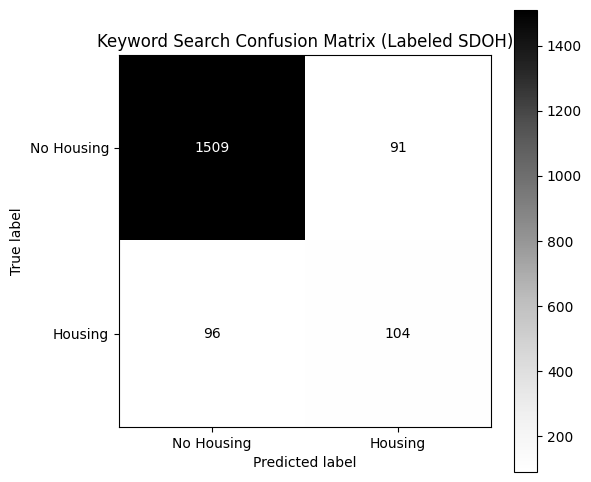

Precision: 0.533
Recall:    0.520
F1:        0.527


In [8]:
y_keyword_pred = X_labeled.apply(keyword_search).values
y_true = y_labeled.values

print('--- Keyword search performance on labeled SDOH (n = 1,800) ---\n')
print(classification_report(y_true, y_keyword_pred, target_names=['No Housing', 'Housing']))

cm_kw = confusion_matrix(y_true, y_keyword_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_kw, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Greys')
plt.title('Keyword Search Confusion Matrix (Labeled SDOH)')
plt.show()

print(f"Precision: {precision_score(y_true, y_keyword_pred):.3f}")
print(f"Recall:    {recall_score(y_true, y_keyword_pred):.3f}")
print(f"F1:        {f1_score(y_true, y_keyword_pred):.3f}")

### 3.3 Apply the keyword search to the MIMIC-IV SMI cohort

We load the 3,808-admission SMI cohort and apply the same regex to each full discharge note.

In [5]:
df = pd.read_csv(f'{DATA_DIR}/df_final.csv')
print(f"SMI cohort: {len(df):,} admissions")
print(f"Columns: {list(df.columns)}")

SMI cohort: 3,808 admissions
Columns: ['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod', 'race_category', 'insurance_category', 'in_hospital_death', 'readmission_30day', 'first_icd_code', 'first_icd_version', 'schizophrenia', 'bipolar_disorder', 'major_depressive_disorder', 'discharge_text', 'discharge_disposition_removed', 'housing_mention']


In [9]:
df['housing_keyword_pred'] = df['discharge_text'].apply(keyword_search)

n_yes = int(df['housing_keyword_pred'].sum())
keyword_rate = n_yes / len(df) * 100
print(f"Keyword search flagged {n_yes:,} / {len(df):,} notes "
      f"({keyword_rate:.2f}%) as containing a housing mention")

Keyword search flagged 3,551 / 3,808 notes (93.25%) as containing a housing mention


#### Refined keyword search applied separately

The list above (28 patterns) leans heavily on broad single-word terms like `home`, `lives`, `house`, `housing` that fire in many non-housing-instability contexts. Here we build a **refined** keyword list (`HOUSING_REGEX_REFINED`) that drops those broad terms and replaces them with phrase patterns (`lives on the street`, `lives in his car`, `staying with friends`, `no permanent address`, `housing situation/status/crisis`, etc.) plus housing-services vocabulary (`transitional housing`, `group home`, `Section 8`, `SRO`, ...). We apply this list separately as `housing_keyword_pred_refined` so we can compare detection rates without changing the original keyword search above.

In [ ]:
HOUSING_REGEX_REFINED = [
    # --- High-precision unambiguous terms ---
    r'\bhomeless(?:ness)?\b',
    r'\bunsheltered\b',
    r'\bencampment(?:s)?\b',
    r'\bevicted\b',
    r'\beviction(?:s)?\b',
    r'\btransient\b',
    r'\bdisplaced\b',
    r'\bprecariously housed\b',
    r'\bcouch[ -]surfing\b',
    r'\bdoubled[ -]up\b',

    # --- Shelter constrained to housing context (avoids "shelter in place") ---
    r'\b(?:homeless|emergency|women\'?s|men\'?s|family) shelter\b',

    # --- "lives in / lives on" and similar phrase patterns ---
    r'\bliv(?:es|ing) (?:on|in) the streets?\b',
    r'\bliv(?:es|ing) in (?:his|her|their) car\b',
    r'\bliv(?:es|ing) in a (?:shelter|tent|car)\b',
    r'\bliv(?:es|ing) in (?:transitional|supportive|subsidized|public) housing\b',
    r'\bliv(?:es|ing) in a (?:group home|halfway house|sober (?:home|house|living))\b',
    r'\bsleep(?:s|ing) (?:in|on) (?:his|her|their) car\b',
    r'\bsleep(?:s|ing) on the streets?\b',
    r'\bsleep(?:s|ing) outside\b',
    r'\bstaying (?:with|at) (?:friends?|family|relatives?)\b',

    # --- Housing instability / insecurity phrases ---
    r'\bhousing instability\b',
    r'\bunstable housing\b',
    r'\binsecure housing\b',
    r'\bhousing insecurity\b',
    r'\bhousing (?:situation|status|issues?|problems?|crisis|needs?)\b',
    r'\bwithout a home\b',
    r'\bwithout (?:stable )?housing\b',
    r'\bno fixed(?: abode| address)?\b',
    r'\bno (?:permanent|stable|fixed) (?:housing|address|home|residence)\b',
    r'\b(?:experiencing|at risk (?:of|for)) homelessness\b',
    r'\blos(?:ing|t) (?:his|her|their) (?:home|housing|apartment|place)\b',
    r'\blosing housing\b',
    r'\blose housing\b',
    r'\bbetween homes?\b',
    r'\bnowhere to (?:go|live|stay)\b',
    r'\bno place to (?:go|live|stay)\b',
    r'\bkicked out (?:of|by)\b',

    # --- Housing-services vocabulary ---
    r'\b(?:transitional|supportive|subsidized|public|low[ -]income) housing\b',
    r'\bgroup home\b',
    r'\bhalfway house\b',
    r'\bsober (?:home|house|living)\b',
    r'\bSRO\b',
    r'\bsingle room occupancy\b',
    r'\bSection 8\b',
    r'\bhousing voucher\b',
]
HOUSING_PATTERN_REFINED = re.compile('|'.join(HOUSING_REGEX_REFINED), re.IGNORECASE)

def keyword_search_refined(text):
    """Return 1 if the text contains any refined housing keyword, else 0."""
    if not isinstance(text, str):
        return 0
    return int(bool(HOUSING_PATTERN_REFINED.search(text)))

df['housing_keyword_pred_refined'] = df['discharge_text'].apply(keyword_search_refined)

n_refined = int(df['housing_keyword_pred_refined'].sum())
pct_refined = n_refined / len(df) * 100
n_original = int(df['housing_keyword_pred'].sum())
pct_original = n_original / len(df) * 100

print(f"Refined keyword list:  {len(HOUSING_REGEX_REFINED)} patterns")
print(f"Original keyword list: {len(HOUSING_REGEX)} patterns")
print()
print(f"Refined search flagged:  {n_refined:,} / {len(df):,} notes ({pct_refined:.2f}%)")
print(f"Original search flagged: {n_original:,} / {len(df):,} notes ({pct_original:.2f}%)")
print(f"Difference: {pct_refined - pct_original:+.2f} percentage points")
print()

# Sample sentences from the SMI cohort matching at least one refined keyword
SENT_RE = re.compile(r'(?<=[.!?])\s+(?=[A-Z])')

matching_refined = []
for hadm, text in zip(df['hadm_id'], df['discharge_text'].fillna('')):
    for sent in SENT_RE.split(text):
        sent = sent.strip()
        if 20 < len(sent) < 400 and HOUSING_PATTERN_REFINED.search(sent):
            matching_refined.append((hadm, sent))
    if len(matching_refined) >= 5000:
        break

print(f"Collected {len(matching_refined):,} candidate matching sentences "
      f"(scan capped at 5,000).")
print()

random.seed(RANDOM_SEED)
sample = random.sample(matching_refined, min(200, len(matching_refined)))
print('=' * 70)
print('Sample sentences matched by the REFINED keyword search')
print('=' * 70)
for hadm, sent in sample:
    if len(sent) > 250:
        sent = sent[:250] + '...'
    highlighted = HOUSING_PATTERN_REFINED.sub(lambda m: f'[{m.group()}]', sent)
    print(f'  [hadm {hadm}] {highlighted}')


### 3.4 Most common housing keywords found

Which specific keywords are firing? Heavy concentration on a few terms would mean the headline rate is not really driven by 28 keywords but by a handful.

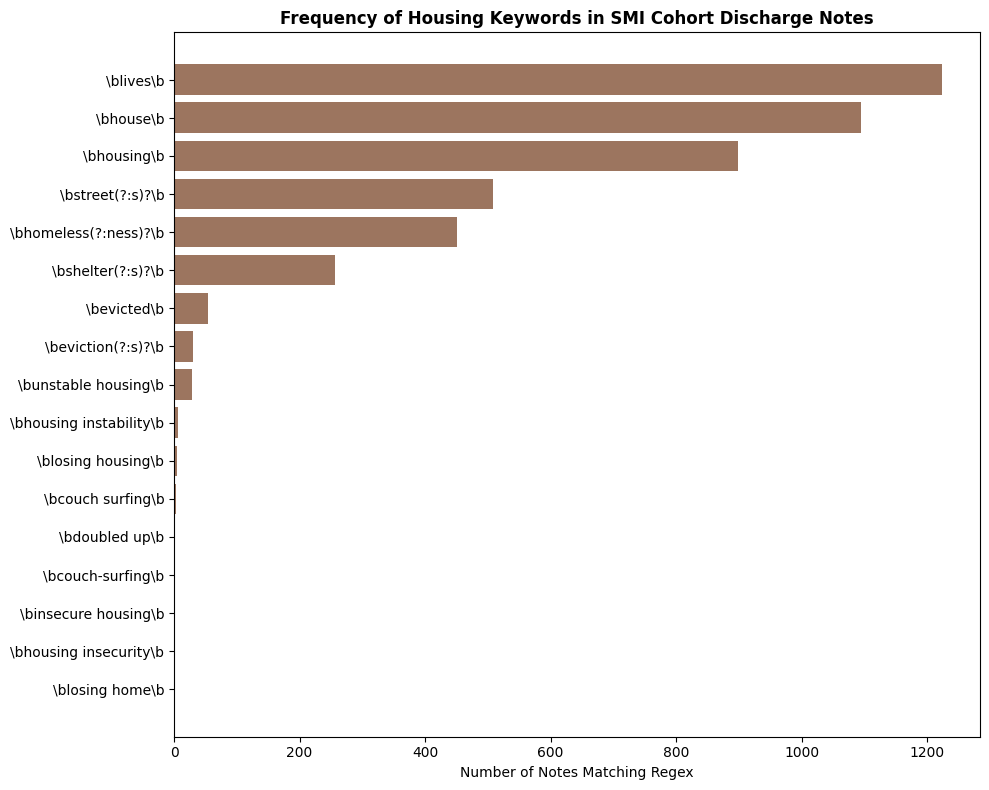

In [14]:
keyword_counts = Counter()
for text in df['discharge_text'].dropna():
    for pat_str, regex in COMPILED_REGEXES.items():
        if regex.search(text):
            keyword_counts[pat_str] += 1

key_df = (
    pd.DataFrame(keyword_counts.most_common(), columns=['Keyword Regex', 'Notes Matched'])
    .sort_values('Notes Matched', ascending=True)
)

plt.figure(figsize=(10, 8))
plt.barh(key_df['Keyword Regex'], key_df['Notes Matched'], color='#9c755f')
plt.title('Frequency of Housing Keywords in SMI Cohort Discharge Notes', fontsize=12, fontweight='bold')
plt.xlabel('Number of Notes Matching Regex')
plt.tight_layout()
plt.show()

### 3.5 Subgroup analysis on the SMI cohort

Demographic break-down of the keyword-search-flagged housing rate, mirroring the Milestone 2 analysis. We use the same four subgroups (race, primary diagnosis, insurance, gender) that we will reuse for the multi-method comparison in §11.

,n,pct_flagged
group,,
Hispanic,241,71.78
White,2350,64.98
Black,754,71.75
Other,463,62.20


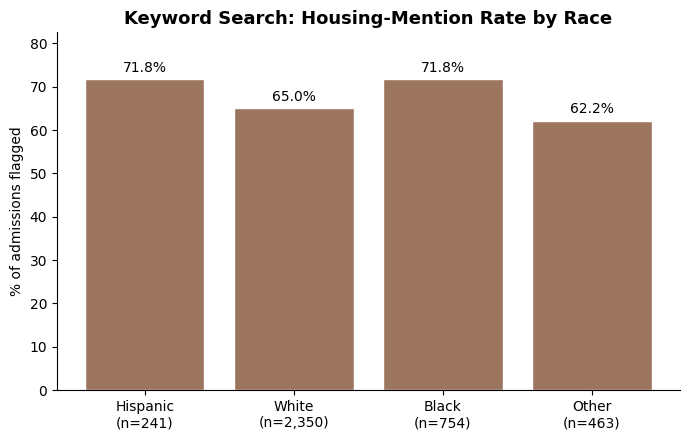

In [15]:
def keyword_subgroup_rates(df, group_col, level_order):
    rows = []
    for level in level_order:
        sub = df[df[group_col] == level]
        if len(sub) == 0:
            continue
        rows.append({
            'group': level,
            'n': len(sub),
            'pct_flagged': sub['housing_keyword_pred'].mean() * 100,
        })
    return pd.DataFrame(rows).set_index('group')


def plot_keyword_subgroup(rate_df, title, color='#9c755f'):
    levels = list(rate_df.index)
    fig, ax = plt.subplots(figsize=(max(7, len(levels) * 1.6), 4.5))
    bars = ax.bar(levels, rate_df['pct_flagged'].values, color=color, edgecolor='white')
    for b, v in zip(bars, rate_df['pct_flagged'].values):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f'{v:.1f}%',
                ha='center', va='bottom', fontsize=10)
    ax.set_xticks(range(len(levels)))
    ax.set_xticklabels([f'{lvl}\n(n={int(rate_df.loc[lvl, "n"]):,})' for lvl in levels])
    ax.set_ylabel('% of admissions flagged')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(rate_df['pct_flagged'].max() * 1.15, 5))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()


# 3.5.1 By race
race_rates_kw = keyword_subgroup_rates(df, 'race_category',
                                        ['Hispanic', 'White', 'Black', 'Other'])
display(race_rates_kw.round(2))
plot_keyword_subgroup(race_rates_kw, 'Keyword Search: Housing-Mention Rate by Race')

,n,pct_flagged
group,,
Schizophrenia,1149,70.58
Bipolar Disorder,1195,66.86
Major Depressive\nDisorder,1464,62.77


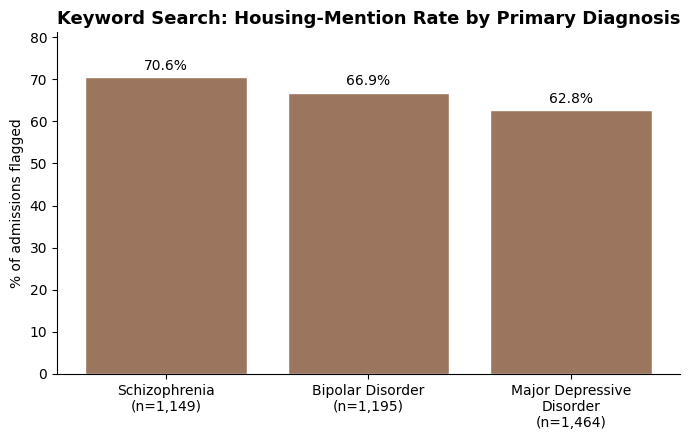

In [16]:
# 3.5.2 By primary diagnosis
dx_cols = ['schizophrenia', 'bipolar_disorder', 'major_depressive_disorder']
dx_labels = {'schizophrenia': 'Schizophrenia',
             'bipolar_disorder': 'Bipolar Disorder',
             'major_depressive_disorder': 'Major Depressive\nDisorder'}
dx_rows = []
for dx in dx_cols:
    sub = df[df[dx] == 1]
    dx_rows.append({'group': dx_labels[dx], 'n': len(sub),
                    'pct_flagged': sub['housing_keyword_pred'].mean() * 100})
dx_rates_kw = pd.DataFrame(dx_rows).set_index('group')
display(dx_rates_kw.round(2))
plot_keyword_subgroup(dx_rates_kw, 'Keyword Search: Housing-Mention Rate by Primary Diagnosis')

,n,pct_flagged
group,,
Medicaid,836,72.85
Medicare,1369,69.83
Private,1229,57.12
Other,374,70.05


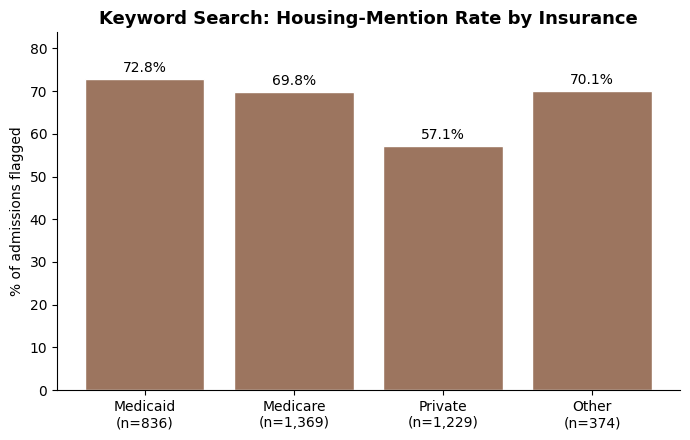

In [17]:
# 3.5.3 By insurance
ins_rates_kw = keyword_subgroup_rates(df, 'insurance_category',
                                       ['Medicaid', 'Medicare', 'Private', 'Other'])
display(ins_rates_kw.round(2))
plot_keyword_subgroup(ins_rates_kw, 'Keyword Search: Housing-Mention Rate by Insurance')

,n,pct_flagged
group,,
F,1941,65.12
M,1867,67.76


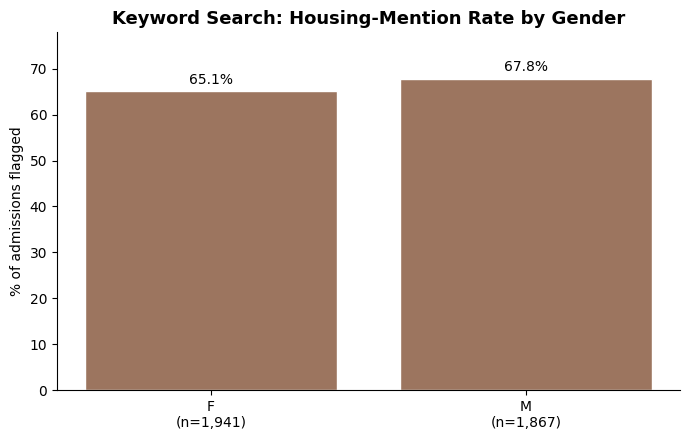

In [18]:
# 3.5.4 By gender
gender_levels = sorted(df['gender'].dropna().unique().tolist())
gender_rates_kw = keyword_subgroup_rates(df, 'gender', gender_levels)
display(gender_rates_kw.round(2))
plot_keyword_subgroup(gender_rates_kw, 'Keyword Search: Housing-Mention Rate by Gender')

## 4. Discharge Note vs. Labeled Sentence Length

Before training learned classifiers we need to deal with a fundamental mismatch between training and inference data: the labeled SDOH dataset consists of **single sentences** (~10-25 words each), while the SMI cohort consists of **full discharge notes** (median ~2,000 words). A model trained on one cannot be applied directly to the other &mdash; we have to split the SMI notes into sentences first.

This section quantifies the mismatch (§4.1), runs the sentence splitter (§4.2), and confirms that post-splitting the two distributions look much more comparable (§4.3).

### 4.1 Full discharge note length: SMI cohort vs. labeled SDOH

A histogram on the same axes shows just how different the two distributions are. The labeled SDOH "documents" are individual sentences; the SMI "documents" are entire notes. This is the motivation for sentence-level inference.

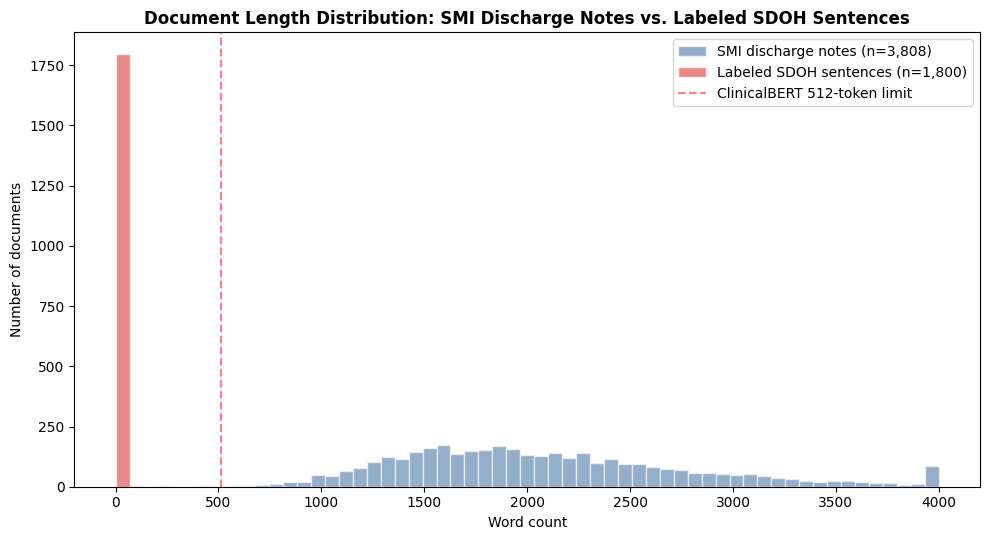

SMI discharge notes:    median = 1979 words, max = 5,623 words
Labeled SDOH sentences: median = 14 words, max = 73 words

=> SMI notes are ~141x longer than the labeled training data.
   Direct note-level inference is infeasible &mdash; we split notes into sentences below.


In [19]:
smi_word_counts = df['discharge_text'].fillna('').apply(lambda x: len(x.split()))
labeled_full_word_counts = labeled_sdoh['text'].fillna('').apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5.5))
bins = np.linspace(0, 4000, 60)
plt.hist(smi_word_counts.clip(upper=4000), bins=bins, alpha=0.6,
         color='#4e79a7', label=f'SMI discharge notes (n={len(smi_word_counts):,})', edgecolor='white')
plt.hist(labeled_full_word_counts.clip(upper=4000), bins=bins, alpha=0.7,
         color='#e15759', label=f'Labeled SDOH sentences (n={len(labeled_full_word_counts):,})',
         edgecolor='white')
plt.axvline(512, linestyle='--', color='red', alpha=0.5, label='ClinicalBERT 512-token limit')
plt.xlabel('Word count')
plt.ylabel('Number of documents')
plt.title('Document Length Distribution: SMI Discharge Notes vs. Labeled SDOH Sentences',
          fontsize=12, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

print(f"SMI discharge notes:    median = {smi_word_counts.median():.0f} words, "
      f"max = {smi_word_counts.max():,} words")
print(f"Labeled SDOH sentences: median = {labeled_full_word_counts.median():.0f} words, "
      f"max = {labeled_full_word_counts.max()} words")
print(f"\n=> SMI notes are ~{smi_word_counts.median() / labeled_full_word_counts.median():.0f}x "
      f"longer than the labeled training data.\n"
      f"   Direct note-level inference is infeasible &mdash; we split notes into sentences below.")

### 4.2 Split SMI discharge notes into narrative sentences (`smi_sentences_filtered`)

We apply our two-stage sentence preprocessor from Milestone 3:

1. **Section-level**: split each note on `Header:` delimiters, drop non-narrative sections (labs, meds, physical exam, identifiers).
2. **Sentence-level**: split remaining sections on `.!?` boundaries, drop fragments that are too short, mostly numeric, mostly uppercase, lab-like, medication orders, or section headers.
3. **Narrative-prose filter**: keep sentences that contain a housing keyword or a subject pronoun (`he`/`she`/`they`); drop the rest if they look like problem-list enumerations (low stopword density, high comma density, or 3+ medical abbreviations).

In [11]:
# Section headers whose content is NOT narrative — skip these sections entirely
NON_NARRATIVE_HEADERS = {
    'pertinent results', 'pertinent labs', 'labs', 'admission labs',
    'discharge labs', 'labs on admission', 'labs on discharge',
    'imaging', 'studies', 'diagnostic studies', 'studies on admission',
    'physical exam', 'physical examination', 'exam', 'admission exam',
    'vitals', 'vital signs',
    'medications', 'medications on admission', 'discharge medications',
    'admission medications', 'home medications',
    'name', 'unit no', 'admission date', 'discharge date', 'date of birth',
    'sex', 'service', 'attending', 'allergies', 'facility',
    'discharge instructions', 'followup instructions', 'followup',
    'discharge disposition', 'major surgical or invasive procedure',
}

HEADER_RE = re.compile(r'\n([A-Z][A-Za-z0-9/\s]{1,60}?):\s*')
LAB_TOKEN_RE = re.compile(r'\b[A-Z]{2,}-[\d.]+')
DOSE_RE      = re.compile(r'\b\d+(?:\.\d+)?\s?(?:mg|mcg|mL|ml|g)\b', re.IGNORECASE)
ROUTE_RE     = re.compile(r'\b(?:PO|IV|IM|SC|IH|SL|PR|PRN)\b')
FREQ_RE      = re.compile(r'\b(?:QHS|QAM|QPM|QID|BID|TID|Q[0-9]+H|QOD|QD)\b', re.IGNORECASE)
SENT_SPLIT_RE = re.compile(r'(?<=[.!?])\s+(?=[A-Z])')

STOP_SET = set(ENGLISH_STOP_WORDS)
MED_ABBREVS = {
    'htn', 'hl', 'hld', 'dm', 'dmii', 'dm2', 't2dm', 'iddm', 'niddm',
    'cad', 'chf', 'copd', 'ckd', 'esrd', 'osa', 'gerd', 'pud', 'ibs',
    'hiv', 'hcv', 'hbv', 'mi', 'cva', 'tia', 'pe', 'dvt', 'afib',
    'bph', 'gout', 'sle', 'mdd', 'gad', 'ptsd', 'ocd',
    'h/o', 's/p', 'r/o', 'c/b',
}
SUBJECT_PRONOUNS = {'he', 'she', 'they'}


def is_narrative_sentence(s):
    s = s.strip()
    s_core = s.replace('___', '').strip()  # ignore placeholders for length checks
    if len(s_core) < 25 or len(s_core.split()) < 5:
        return False
    letters = sum(c.isalpha() for c in s_core)
    if letters / max(len(s_core), 1) < 0.6:
        return False
    if sum(c.isupper() for c in s_core) / max(letters, 1) > 0.4:
        return False
    if LAB_TOKEN_RE.search(s):
        return False
    if len(DOSE_RE.findall(s)) + len(ROUTE_RE.findall(s)) + len(FREQ_RE.findall(s)) >= 2:
        return False
    if s.rstrip().rstrip('.!?').endswith(':'):
        return False
    return True


def is_narrative_prose(s):
    s = str(s)
    tokens = re.findall(r"\b[\w/']+\b", s.lower())
    if len(tokens) < 5:
        return False
    if HOUSING_PATTERN.search(s):
        return True
    if any(t in SUBJECT_PRONOUNS for t in tokens):
        return True
    if sum(t in STOP_SET for t in tokens) / len(tokens) < 0.15:
        return False
    if s.count(',') / max(len(s.split()), 1) > 0.20:
        return False
    if sum(t in MED_ABBREVS for t in tokens) >= 3:
        return False
    return True


def note_to_sentences(note):
    """Split a discharge note into clean narrative sentences, section by section."""
    if not isinstance(note, str) or not note.strip():
        return []
    parts = HEADER_RE.split('\n' + note)
    if len(parts) < 3:
        return []
    sentences = []
    for i in range(1, len(parts), 2):
        header = parts[i].strip().lower()
        content = parts[i + 1] if i + 1 < len(parts) else ''
        if header in NON_NARRATIVE_HEADERS:
            continue
        content = re.sub(r'\s+', ' ', content).strip()
        if not content:
            continue
        for s in SENT_SPLIT_RE.split(content):
            if is_narrative_sentence(s) and is_narrative_prose(s):
                sentences.append(s.strip())
    return sentences


print("Extracting narrative sentences from SMI discharge notes...")
sentence_rows = []
for _, row in tqdm(df.iterrows(), total=len(df)):
    for s in note_to_sentences(row['discharge_text']):
        sentence_rows.append({'hadm_id': row['hadm_id'], 'sentence_text': s})

smi_sentences_filtered = pd.DataFrame(sentence_rows)
print(f"Extracted {len(smi_sentences_filtered):,} narrative sentences from {len(df):,} notes "
      f"(avg {len(smi_sentences_filtered) / len(df):.1f} per note)")
print(f"Notes covered: {smi_sentences_filtered['hadm_id'].nunique():,} / {len(df):,}")


Extracting narrative sentences from SMI discharge notes...


  0%|          | 0/3808 [00:00<?, ?it/s]

Extracted 226,129 narrative sentences from 3,808 notes (avg 59.4 per note)
Notes covered: 3,808 / 3,808


### 4.3 Sentence length distribution: SMI sentences vs. labeled SDOH sentences

After splitting, both corpora are at the same granularity. The two distributions should now overlap substantially &mdash; confirming that what we feed the classifier at inference time looks like what it saw during training.

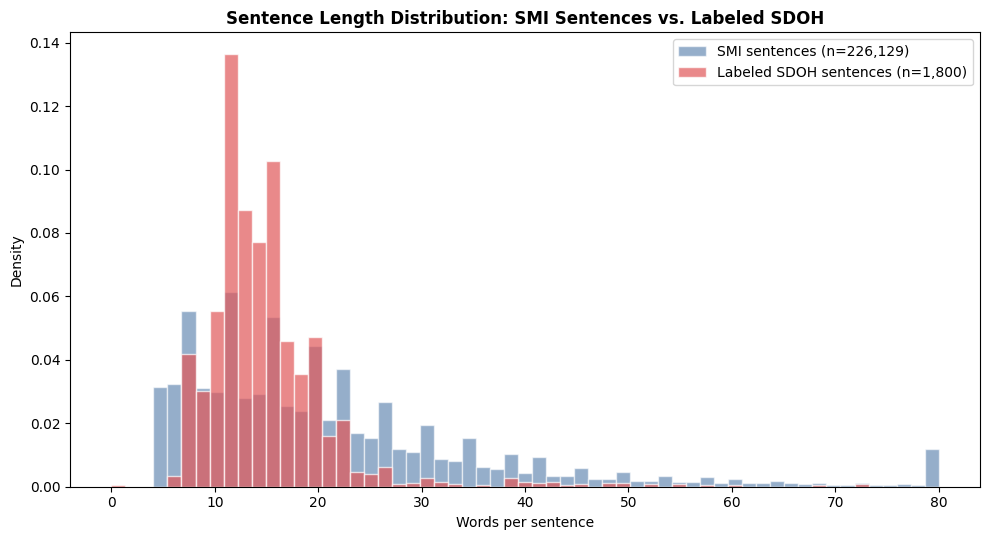

SMI sentences:     median = 17 words, 95th pct = 53
Labeled sentences: median = 14 words, 95th pct = 24


In [12]:
smi_sent_lens = smi_sentences_filtered['sentence_text'].apply(lambda s: len(s.split()))
labeled_sent_lens = labeled_sdoh['text'].apply(lambda s: len(str(s).split()))

plt.figure(figsize=(10, 5.5))
bins = np.linspace(0, 80, 60)
plt.hist(smi_sent_lens.clip(upper=80), bins=bins, alpha=0.6, density=True,
         color='#4e79a7', label=f'SMI sentences (n={len(smi_sent_lens):,})', edgecolor='white')
plt.hist(labeled_sent_lens.clip(upper=80), bins=bins, alpha=0.7, density=True,
         color='#e15759', label=f'Labeled SDOH sentences (n={len(labeled_sent_lens):,})',
         edgecolor='white')
plt.xlabel('Words per sentence')
plt.ylabel('Density')
plt.title('Sentence Length Distribution: SMI Sentences vs. Labeled SDOH',
          fontsize=12, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

print(f"SMI sentences:     median = {smi_sent_lens.median():.0f} words, "
      f"95th pct = {smi_sent_lens.quantile(0.95):.0f}")
print(f"Labeled sentences: median = {labeled_sent_lens.median():.0f} words, "
      f"95th pct = {labeled_sent_lens.quantile(0.95):.0f}")

### 4.4 Sample sentences containing broad housing-adjacent terms

The four most generic keywords in our list — `home`, `lives`, `house`, `housing` — can appear in non-housing-instability contexts (e.g. "discharged home in stable condition"). Now that the notes have been split into sentences we can inspect actual sentence examples to understand how often each term carries a housing-instability meaning vs. being incidental. This motivates training a learned classifier rather than relying on the keyword list alone.

In [ ]:
BROAD_TERMS = {
    'home':    re.compile(r'\bhome\b', re.IGNORECASE),
    'lives':   re.compile(r'\blives\b', re.IGNORECASE),
    'house':   re.compile(r'\bhouse\b', re.IGNORECASE),
    'housing': re.compile(r'\bhousing\b', re.IGNORECASE),
}

N_SAMPLES = 5

for term, pattern in BROAD_TERMS.items():
    hits = smi_sentences_filtered.loc[
        smi_sentences_filtered['sentence_text'].apply(lambda s: bool(pattern.search(s))),
        'sentence_text'
    ].tolist()

    sample = random.sample(hits, min(N_SAMPLES, len(hits)))

    print('=' * 70)
    print(f'Keyword "\\b{term}\\b" — {len(hits):,} matching sentences in smi_sentences_filtered')
    print('=' * 70)
    for sent in sample:
        if len(sent) > 220:
            sent = sent[:220] + '...'
        highlighted = pattern.sub(lambda m: f'[{m.group()}]', sent)
        print(f'  {highlighted}')
    print()


### 4.5 Sentences that are clearly NOT housing mentions

The simplest possible definition of a "not housing" sentence: one that matches **neither** the original keyword list (`HOUSING_REGEX`) **nor** the refined one (`HOUSING_REGEX_REFINED`). Any sentence flagged by either of those lists is a possible housing mention, so by complement, sentences flagged by neither are very likely about something else (labs, vitals, medications, exam findings, etc.). This gives us a high-precision pool of "definitely-not-housing" sentences without having to maintain a separate negative-keyword list.

In [ ]:
def is_definitely_not_housing(text):
    """A sentence is 'definitely not housing' iff neither keyword list fires on it."""
    if not isinstance(text, str):
        return False
    if HOUSING_PATTERN.search(text):
        return False
    if HOUSING_PATTERN_REFINED.search(text):
        return False
    return True

smi_sentences_filtered['not_housing_keyword_pred'] = (
    smi_sentences_filtered['sentence_text'].apply(is_definitely_not_housing).astype(int)
)

n_not = int(smi_sentences_filtered['not_housing_keyword_pred'].sum())
n_total = len(smi_sentences_filtered)
print(f"Sentences with no housing keywords (either list):  "
      f"{n_not:,} / {n_total:,} ({n_not / n_total * 100:.2f}%)")
print(f"Sentences with at least one housing keyword match: "
      f"{n_total - n_not:,} / {n_total:,} ({(n_total - n_not) / n_total * 100:.2f}%)")
print()

# Show 15 random samples
not_housing_sample = smi_sentences_filtered.loc[
    smi_sentences_filtered['not_housing_keyword_pred'] == 1
].sample(min(100, n_not), random_state=RANDOM_SEED)

print('=' * 70)
print('Sample sentences with no housing keyword match (likely NOT housing mentions)')
print('=' * 70)
for _, r in not_housing_sample.iterrows():
    sent = r['sentence_text']
    if len(sent) > 250:
        sent = sent[:250] + '...'
    print(f'  [hadm {r["hadm_id"]}] {sent}')


## 5. TF-IDF + Random Forest

The first learned baseline: a TF-IDF vectorizer (unigrams + bigrams, 5k features) feeding a Random Forest with `class_weight='balanced'`. Hyperparameters tuned with a small grid search on the labeled training split.

### 5.1 Train + grid search on the labeled SDOH

In [23]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')
rf = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_SEED)

rf_pipeline = Pipeline([
    ('tfidf', tfidf),
    ('classifier', rf),
])

param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [None, 10, 20],
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid, cv=3, scoring='f1', n_jobs=-1, verbose=1,
)

print("Fitting TF-IDF + Random Forest grid search...")
grid_search.fit(X_train, y_train)
rf_model = grid_search.best_estimator_
print(f"\nBest parameters: {grid_search.best_params_}")

Fitting TF-IDF + Random Forest grid search...
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best parameters: {'classifier__max_depth': None, 'classifier__n_estimators': 100}


### 5.2 Validation evaluation

--- TF-IDF + Random Forest validation report ---

              precision    recall  f1-score   support

  No Housing       0.98      1.00      0.99       320
     Housing       1.00      0.80      0.89        40

    accuracy                           0.98       360
   macro avg       0.99      0.90      0.94       360
weighted avg       0.98      0.98      0.98       360



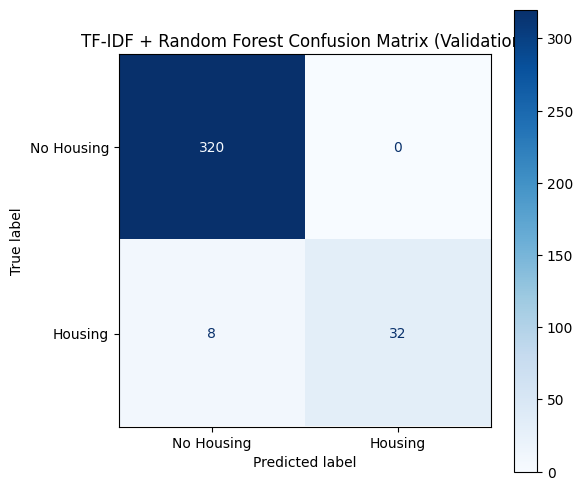

In [24]:
y_rf_pred = rf_model.predict(X_val)

print('--- TF-IDF + Random Forest validation report ---\n')
print(classification_report(y_val, y_rf_pred, target_names=['No Housing', 'Housing']))

cm_rf = confusion_matrix(y_val, y_rf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Blues')
plt.title('TF-IDF + Random Forest Confusion Matrix (Validation)')
plt.show()

## 6. Word2Vec + MLP

The second learned baseline. We train custom 100-dimensional Word2Vec embeddings on the SMI sentence corpus (so the embeddings see real clinical writing), then mean-pool each labeled sentence into a single vector and feed it to a 2-hidden-layer MLP. The MLP threshold is F1-tuned on the validation split.

### 6.1 Train Word2Vec on the SMI sentence corpus

In [25]:
from gensim.models import Word2Vec

def basic_tokenize(text):
    return [w.lower() for w in re.findall(r'\b\w+\b', str(text))]

print("Tokenizing SMI sentence corpus for Word2Vec...")
w2v_corpus = [basic_tokenize(s) for s in smi_sentences_filtered['sentence_text']]

print(f"Training Word2Vec on {len(w2v_corpus):,} clinical sentences...")
w2v_model = Word2Vec(
    sentences=w2v_corpus,
    vector_size=100, window=5, min_count=3, workers=1, seed=RANDOM_SEED,
)

print("\nMost similar to 'homeless':")
try:
    display(w2v_model.wv.most_similar('homeless', topn=5))
except KeyError:
    print("  (not in vocabulary)")

Tokenizing SMI sentence corpus for Word2Vec...
Training Word2Vec on 225,845 clinical sentences...

Most similar to 'homeless':


[('unemployed', 0.7292743921279907),
 ('married', 0.6218041181564331),
 ('sober', 0.6156817674636841),
 ('living', 0.5899773836135864),
 ('employed', 0.5892505645751953)]

### 6.2 Vectorize labeled sentences and SMI sentences

In [26]:
def sentence_to_avg_vector(text, model, vector_size=100):
    words = basic_tokenize(text)
    vecs = [model.wv[w] for w in words if w in model.wv.key_to_index]
    if not vecs:
        return np.zeros(vector_size)
    return np.mean(vecs, axis=0)

print("Vectorizing labeled train/val + SMI sentences...")
X_train_vec = np.array([sentence_to_avg_vector(t, w2v_model) for t in X_train])
X_val_vec   = np.array([sentence_to_avg_vector(t, w2v_model) for t in X_val])
X_smi_vec   = np.array([sentence_to_avg_vector(t, w2v_model)
                        for t in smi_sentences_filtered['sentence_text']])
print(f"Train: {X_train_vec.shape}, Val: {X_val_vec.shape}, SMI: {X_smi_vec.shape}")

Vectorizing labeled train/val + SMI sentences...
Train: (1440, 100), Val: (360, 100), SMI: (225845, 100)


### 6.3 Train the MLP and tune the classification threshold

Following the Milestone 3 procedure, we oversample the minority (housing) class with `RandomOverSampler` so that the MLP sees a balanced training distribution (~1,280 positive / 1,280 negative after resampling). We then tune the decision threshold on the held-out validation set to maximize F1 &mdash; this counteracts the over-flagging behavior we saw with the default 0.5 threshold in MS3.

After oversampling: 2,560 sentences (1280 positive, 1280 negative)
Training MLP on oversampled data...
Default 0.50 -> F1 = 0.717
Tuned 0.827 -> F1 = 0.795  (precision 0.879, recall 0.725)

--- Word2Vec + MLP validation report (tuned threshold) ---

              precision    recall  f1-score   support

  No Housing       0.97      0.99      0.98       320
     Housing       0.88      0.72      0.79        40

    accuracy                           0.96       360
   macro avg       0.92      0.86      0.89       360
weighted avg       0.96      0.96      0.96       360



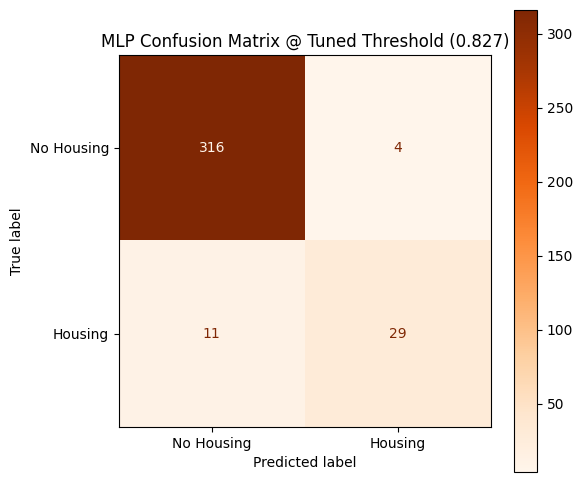

In [27]:
from imblearn.over_sampling import RandomOverSampler

mlp_model = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    max_iter=500,
    early_stopping=True,
    random_state=RANDOM_SEED,
)

# Oversample the minority (housing) class so the MLP sees balanced classes during training
# (matches the Milestone 3 training procedure).
ros = RandomOverSampler(random_state=RANDOM_SEED)
X_train_res, y_train_res = ros.fit_resample(X_train_vec, y_train)
print(f"After oversampling: {len(X_train_res):,} sentences "
      f"({(y_train_res == 1).sum()} positive, {(y_train_res == 0).sum()} negative)")

print("Training MLP on oversampled data...")
mlp_model.fit(X_train_res, y_train_res)

# Tune threshold on validation
val_proba_mlp = mlp_model.predict_proba(X_val_vec)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba_mlp)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-10)
best_idx_mlp = int(np.argmax(f1s))
best_threshold_mlp = float(thresholds[best_idx_mlp])

print(f"Default 0.50 -> F1 = {f1_score(y_val, (val_proba_mlp >= 0.5).astype(int)):.3f}")
print(f"Tuned {best_threshold_mlp:.3f} -> F1 = {f1s[best_idx_mlp]:.3f}  "
      f"(precision {precisions[best_idx_mlp]:.3f}, recall {recalls[best_idx_mlp]:.3f})")

y_mlp_val_pred = (val_proba_mlp >= best_threshold_mlp).astype(int)

print('\n--- Word2Vec + MLP validation report (tuned threshold) ---\n')
print(classification_report(y_val, y_mlp_val_pred, target_names=['No Housing', 'Housing']))

cm_mlp = confusion_matrix(y_val, y_mlp_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Oranges')
plt.title(f'MLP Confusion Matrix @ Tuned Threshold ({best_threshold_mlp:.3f})')
plt.show()


## 7. Fine-tune Bio_ClinicalBERT

Our final model: [`emilyalsentzer/Bio_ClinicalBERT`](https://huggingface.co/emilyalsentzer/Bio_ClinicalBERT), a BERT-base pretrained on MIMIC-III clinical text. We fine-tune at the sentence level with a class-weighted cross-entropy loss to handle the 11/89 class imbalance, then F1-tune the classification threshold on validation. The fine-tuned weights and threshold are saved to Google Drive so subsequent runs skip retraining.

> **Scope note:** Milestone 3's pipeline diagram listed weakly-labeled MIMIC-IV sentences (regex-caught + manually reviewed) as an optional augmentation. We are intentionally **excluding** those weak labels here so that the model is trained only on gold-standard MIMIC-III annotations.

### 7.1 Tokenization

In [16]:
MODEL_NAME = 'emilyalsentzer/Bio_ClinicalBERT'
MAX_LENGTH = 128  # labeled sentences are short; 128 tokens covers ~99% without truncation

# Fine-tuned model is saved here so it survives across Colab sessions
SAVE_PATH = f'{DATA_DIR}/clinicalbert_housing_finetuned'
ALREADY_TRAINED = os.path.exists(SAVE_PATH)

if ALREADY_TRAINED:
    print(f"Saved model found at {SAVE_PATH} — will load instead of retraining.")
    tokenizer = AutoTokenizer.from_pretrained(SAVE_PATH)
else:
    print("No saved model found — will fine-tune from scratch.")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH)

Saved model found at drive/MyDrive/AC209b-project-data/clinicalbert_housing_finetuned — will load instead of retraining.


### 7.2 Build Hugging Face datasets

In [17]:
train_df = pd.DataFrame({'text': X_train.values, 'labels': y_train.values})
val_df   = pd.DataFrame({'text': X_val.values,   'labels': y_val.values})

train_ds = Dataset.from_pandas(train_df, preserve_index=False)
val_ds   = Dataset.from_pandas(val_df,   preserve_index=False)

train_ds = train_ds.map(tokenize_batch, batched=True, remove_columns=['text'])
val_ds   = val_ds.map(tokenize_batch,   batched=True, remove_columns=['text'])

print(train_ds)
print(val_ds)

Map:   0%|          | 0/1440 [00:00<?, ? examples/s]

Map:   0%|          | 0/360 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1440
})
Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 360
})


### 7.3 Class-weighted Trainer

Hugging Face's `Trainer` does not natively accept class weights, so we subclass it and override `compute_loss`. Class weights are derived from training-set frequencies via `compute_class_weight('balanced', ...)`.

In [18]:
class_weight_array = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=y_train.values,
)
class_weights_t = torch.tensor(class_weight_array, dtype=torch.float)
print(f"Class weights (neg, pos): {class_weight_array}")


class WeightedLossTrainer(Trainer):
    """Trainer subclass that applies class-weighted CrossEntropyLoss."""

    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self._class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=self._class_weights.to(logits.device))
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    """Validation metrics each epoch (default 0.5 threshold; tuned in §7.6)."""
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'f1':     f1_score(labels, preds, zero_division=0),
        'recall': (preds[labels == 1] == 1).mean() if (labels == 1).any() else 0.0,
    }

Class weights (neg, pos): [0.5625 4.5   ]


In [19]:
if ALREADY_TRAINED:
    bert_model = AutoModelForSequenceClassification.from_pretrained(SAVE_PATH, num_labels=2)
    print("Loaded fine-tuned model from Drive.")
    trainer = None
else:
    bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    OUTPUT_DIR = 'clinicalbert_housing_run'

    training_args = TrainingArguments(
        output_dir=OUTPUT_DIR,
        num_train_epochs=3,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        greater_is_better=True,
        save_total_limit=1,
        seed=RANDOM_SEED,
        report_to='none',
    )

    data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

    trainer = WeightedLossTrainer(
        model=bert_model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
        class_weights=class_weights_t,
    )

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loaded fine-tuned model from Drive.


### 7.4 Train (or skip if already trained)

In [17]:
if ALREADY_TRAINED:
    print("Skipping fine-tuning — model already loaded from Drive.")
else:
    train_result = trainer.train()
    print(train_result)

Skipping fine-tuning — model already loaded from Drive.


### 7.5 Save model + tokenizer to Drive

In [18]:
if not ALREADY_TRAINED:
    os.makedirs(SAVE_PATH, exist_ok=True)
    trainer.save_model(SAVE_PATH)
    tokenizer.save_pretrained(SAVE_PATH)
    print(f"Model and tokenizer saved to {SAVE_PATH}")
else:
    print("Model was loaded from Drive — no save needed.")

Model was loaded from Drive — no save needed.


### 7.6 Threshold tuning on validation

As with the MLP, we sweep the decision threshold on validation and pick the F1-maximizing value. The tuned threshold is also saved to Drive so it persists across sessions.

In [27]:
THRESHOLD_PATH = f'{SAVE_PATH}/best_threshold.json'

if os.path.exists(THRESHOLD_PATH):
    with open(THRESHOLD_PATH) as _f:
        best_threshold_bert = json.load(_f)['best_threshold']
    print(f"Loaded saved threshold: {best_threshold_bert:.3f}")
    if trainer is not None:
        val_pred_output = trainer.predict(val_ds)
        val_logits = val_pred_output.predictions
    else:
        from torch.utils.data import DataLoader
        bert_model.eval()
        bert_model.to(device)
        loader = DataLoader(val_ds, batch_size=32, collate_fn=DataCollatorWithPadding(tokenizer))
        all_logits = []
        with torch.no_grad():
            for batch in loader:
                batch = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
                all_logits.append(bert_model(**batch).logits.cpu())
        val_logits = torch.cat(all_logits).numpy()
    val_proba_bert = torch.softmax(torch.tensor(val_logits), dim=-1)[:, 1].numpy()
    y_val_arr = np.asarray(y_val)
    precisions_b, recalls_b, thresholds_b = precision_recall_curve(y_val_arr, val_proba_bert)
    f1s_b = 2 * precisions_b[:-1] * recalls_b[:-1] / (precisions_b[:-1] + recalls_b[:-1] + 1e-10)
    best_idx_bert = int(np.argmax(f1s_b))
else:
    val_pred_output = trainer.predict(val_ds)
    val_logits = val_pred_output.predictions
    val_proba_bert = torch.softmax(torch.tensor(val_logits), dim=-1)[:, 1].numpy()
    y_val_arr = np.asarray(y_val)
    precisions_b, recalls_b, thresholds_b = precision_recall_curve(y_val_arr, val_proba_bert)
    f1s_b = 2 * precisions_b[:-1] * recalls_b[:-1] / (precisions_b[:-1] + recalls_b[:-1] + 1e-10)
    best_idx_bert = int(np.argmax(f1s_b))
    best_threshold_bert = float(thresholds_b[best_idx_bert])
    with open(THRESHOLD_PATH, 'w') as _f:
        json.dump({'best_threshold': best_threshold_bert}, _f)
    print(f"Threshold saved to {THRESHOLD_PATH}")

default_pred = (val_proba_bert >= 0.5).astype(int)
tuned_pred   = (val_proba_bert >= best_threshold_bert).astype(int)

print(f"Default 0.50 -> F1 = {f1_score(y_val_arr, default_pred):.3f}")
print(f"Tuned {best_threshold_bert:.3f} -> F1 = {f1s_b[best_idx_bert]:.3f}  "
      f"(precision {precisions_b[best_idx_bert]:.3f}, recall {recalls_b[best_idx_bert]:.3f})")

Loaded saved threshold: 0.054
Default 0.50 -> F1 = 0.949
Tuned 0.054 -> F1 = 0.988  (precision 0.976, recall 1.000)


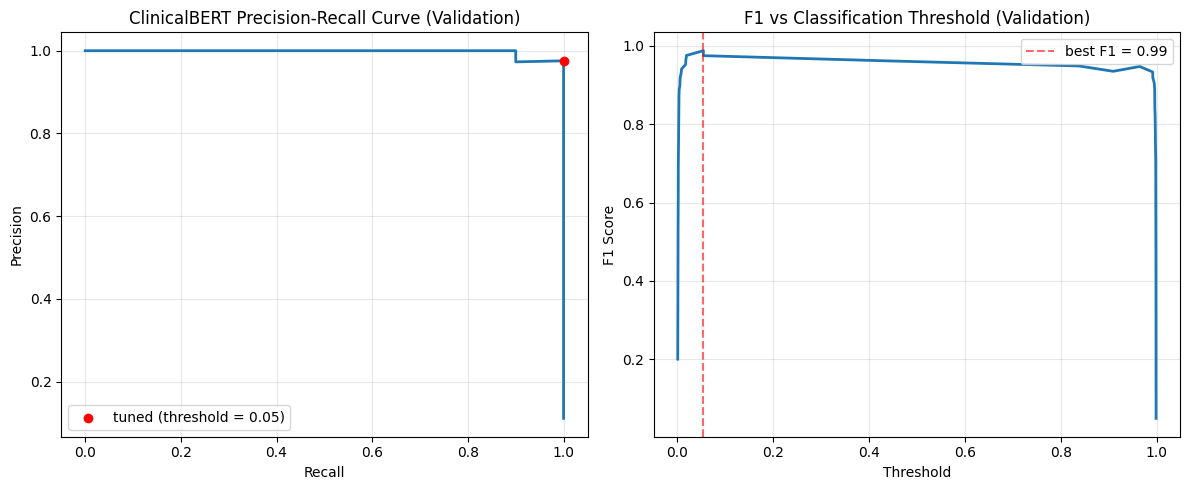

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.plot(recalls_b, precisions_b, linewidth=2)
ax1.scatter(recalls_b[best_idx_bert], precisions_b[best_idx_bert], color='red', zorder=5,
            label=f'tuned (threshold = {best_threshold_bert:.2f})')
ax1.set_xlabel('Recall'); ax1.set_ylabel('Precision')
ax1.set_title('ClinicalBERT Precision-Recall Curve (Validation)')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(thresholds_b, f1s_b, linewidth=2)
ax2.axvline(best_threshold_bert, linestyle='--', color='red', alpha=0.6,
            label=f'best F1 = {f1s_b[best_idx_bert]:.2f}')
ax2.set_xlabel('Threshold'); ax2.set_ylabel('F1 Score')
ax2.set_title('F1 vs Classification Threshold (Validation)')
ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

--- ClinicalBERT validation report @ tuned threshold ---

              precision    recall  f1-score   support

  No Housing       1.00      1.00      1.00       320
     Housing       0.97      0.97      0.97        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



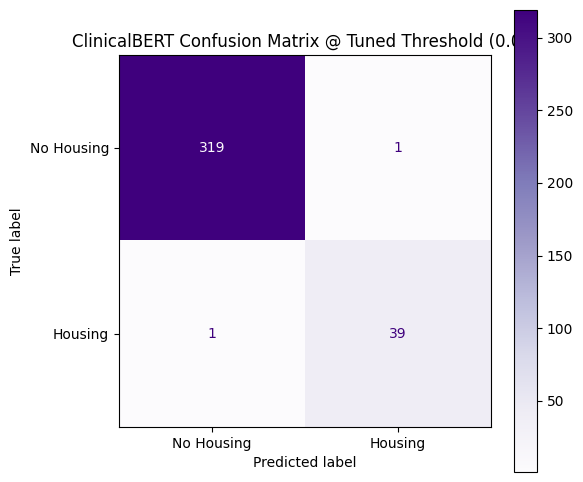

In [21]:
print('--- ClinicalBERT validation report @ tuned threshold ---\n')
print(classification_report(y_val_arr, tuned_pred, target_names=['No Housing', 'Housing']))

cm_bert = confusion_matrix(y_val_arr, tuned_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_bert, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Purples')
plt.title(f'ClinicalBERT Confusion Matrix @ Tuned Threshold ({best_threshold_bert:.2f})')
plt.show()

## 8. Apply Learned Models to the SMI Cohort

We score every sentence in `smi_sentences_filtered` with each of the three learned models, threshold appropriately, and aggregate to the admission level by taking the **max** sentence-level prediction within each `hadm_id` (a note is flagged if any sentence is flagged). ClinicalBERT predictions are cached to Drive so the ~3 hour inference pass runs only once.

### 8.1 Random Forest inference

In [22]:
print("Running Random Forest inference on SMI sentences...")
smi_sentences_filtered['housing_rf_pred'] = rf_model.predict(
    smi_sentences_filtered['sentence_text']
)

note_preds_rf = (
    smi_sentences_filtered.groupby('hadm_id')['housing_rf_pred']
    .max().reset_index()
    .rename(columns={'housing_rf_pred': 'housing_rf_pred'})
)
df = df.drop(columns=['housing_rf_pred'], errors='ignore').merge(
    note_preds_rf, on='hadm_id', how='left'
)
df['housing_rf_pred'] = df['housing_rf_pred'].fillna(0).astype(int)

n_rf = int(df['housing_rf_pred'].sum())
print(f"TF-IDF + RF flagged {n_rf:,} / {len(df):,} notes ({n_rf/len(df)*100:.2f}%)")

Running Random Forest inference on SMI sentences...


NameError: name 'rf_model' is not defined

### 8.2 Word2Vec + MLP inference

In [38]:
print(f"Running MLP inference (threshold = {best_threshold_mlp:.3f})...")
smi_proba_mlp = mlp_model.predict_proba(X_smi_vec)[:, 1]
smi_sentences_filtered['housing_mlp_proba'] = smi_proba_mlp
smi_sentences_filtered['housing_mlp_pred']  = (smi_proba_mlp >= best_threshold_mlp).astype(int)

note_preds_mlp = (
    smi_sentences_filtered.groupby('hadm_id')['housing_mlp_pred']
    .max().reset_index()
    .rename(columns={'housing_mlp_pred': 'housing_mlp_pred'})
)
df = df.drop(columns=['housing_mlp_pred'], errors='ignore').merge(
    note_preds_mlp, on='hadm_id', how='left'
)
df['housing_mlp_pred'] = df['housing_mlp_pred'].fillna(0).astype(int)

n_mlp = int(df['housing_mlp_pred'].sum())
print(f"Word2Vec + MLP flagged {n_mlp:,} / {len(df):,} notes ({n_mlp/len(df)*100:.2f}%)")

Running MLP inference (threshold = 0.827)...
Word2Vec + MLP flagged 2,406 / 3,808 notes (63.18%)


### 8.3 ClinicalBERT inference (cached)

If the predictions CSV already exists on Drive we just load it; otherwise we run inference (~3 hours on CPU, ~5 min on T4 GPU) and save the result.

In [28]:
from torch.utils.data import DataLoader

@torch.no_grad()
def bert_predict_proba(sentences, model, tokenizer, device,
                       batch_size=64, max_length=MAX_LENGTH):
    """Score a list/Series of sentences with the fine-tuned BERT model. Returns P(housing)."""
    model.eval()
    model.to(device)
    sentences = list(sentences)
    out = []
    for i in tqdm(range(0, len(sentences), batch_size), desc='BERT inference'):
        batch = sentences[i:i + batch_size]
        enc = tokenizer(batch, truncation=True, max_length=max_length,
                        padding=True, return_tensors='pt')
        enc = {k: v.to(device) for k, v in enc.items()}
        logits = model(**enc).logits
        proba = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
        out.append(proba)
    return np.concatenate(out)

In [26]:
PREDS_BERT_PATH = f'{DATA_DIR}/smi_sentences_filtered_bert_preds.csv'

if os.path.exists(PREDS_BERT_PATH):
    print(f"Loading saved BERT predictions from {PREDS_BERT_PATH}...")
    bert_preds_df = pd.read_csv(PREDS_BERT_PATH)
    # Merge in case smi_sentences_filtered was re-built fresh in this session
    smi_sentences_filtered = smi_sentences_filtered.merge(
        bert_preds_df[['hadm_id', 'sentence_text', 'housing_bert_proba', 'housing_bert_pred']],
        on=['hadm_id', 'sentence_text'], how='left',
    )
    n_loaded = smi_sentences_filtered['housing_bert_pred'].notna().sum()
    print(f"Merged BERT predictions for {n_loaded:,} / {len(smi_sentences_filtered):,} sentences.")
else:
    smi_sentences_filtered['housing_bert_proba'] = bert_predict_proba(
        smi_sentences_filtered['sentence_text'], bert_model, tokenizer, device
    )
    smi_sentences_filtered['housing_bert_pred'] = (
        smi_sentences_filtered['housing_bert_proba'] >= best_threshold_bert
    ).astype(int)
    smi_sentences_filtered[['hadm_id', 'sentence_text',
                            'housing_bert_proba', 'housing_bert_pred']].to_csv(
        PREDS_BERT_PATH, index=False
    )
    print(f"Predictions saved to {PREDS_BERT_PATH}")

# Aggregate to admission level
smi_sentences_filtered['housing_bert_pred'] = (
    smi_sentences_filtered['housing_bert_pred'].fillna(0).astype(int)
)
note_preds_bert = (
    smi_sentences_filtered.groupby('hadm_id')['housing_bert_pred']
    .max().reset_index()
)
df = df.drop(columns=['housing_bert_pred'], errors='ignore').merge(
    note_preds_bert, on='hadm_id', how='left'
)
df['housing_bert_pred'] = df['housing_bert_pred'].fillna(0).astype(int)

n_bert = int(df['housing_bert_pred'].sum())
print(f"ClinicalBERT flagged {n_bert:,} / {len(df):,} notes ({n_bert/len(df)*100:.2f}%)")

Loading saved BERT predictions from drive/MyDrive/AC209b-project-data/smi_sentences_filtered_bert_preds.csv...
Merged BERT predictions for 228,213 / 228,213 sentences.
ClinicalBERT flagged 3,808 / 3,808 notes (100.00%)


## 9. Sample Sentences Flagged as Housing Mentions

A qualitative spot-check of what each model is actually flagging. We pull 10 random sentences flagged by each model so we can compare what RF, MLP, and ClinicalBERT think a "housing mention" looks like.

In [ ]:
def show_flagged_samples(df_sentences, pred_col, label, n=10):
    flagged = df_sentences.loc[df_sentences[pred_col] == 1]
    print(f"\n{'='*70}\n{label}: {len(flagged):,} flagged sentences ({len(flagged)/len(df_sentences)*100:.2f}% of all)\n{'='*70}")
    sample = flagged.sample(min(n, len(flagged)), random_state=RANDOM_SEED)
    for _, r in sample.iterrows():
        text = r['sentence_text']
        if len(text) > 200:
            text = text[:200] + '...'
        print(f"  [hadm {r['hadm_id']}] {text}")

show_flagged_samples(smi_sentences_filtered, 'housing_rf_pred',   'TF-IDF + Random Forest')
show_flagged_samples(smi_sentences_filtered, 'housing_mlp_pred',  'Word2Vec + MLP')
show_flagged_samples(smi_sentences_filtered, 'housing_bert_pred', 'ClinicalBERT')

### 9.1 Per-sentence model agreement

For each SMI sentence we record which of the four methods flagged it as positive and how many agreed. The keyword search is applied at the sentence level here (rather than the note level used in §3) so all four methods are directly comparable. We then show 10 sentences where **all four methods agreed positive** and 10 where **all four agreed negative** &mdash; the cleanest cases of inter-method consensus.

In [ ]:
# Apply keyword search at the sentence level (note-level was done in §3)
smi_sentences_filtered['housing_keyword_pred'] = (
    smi_sentences_filtered['sentence_text'].apply(keyword_search)
)

# Per-sentence prediction matrix and agreement count
SENT_METHODS = [
    ('housing_keyword_pred', 'Keyword'),
    ('housing_rf_pred',      'RF'),
    ('housing_mlp_pred',     'MLP'),
    ('housing_bert_pred',    'BERT'),
]

def models_flagging(row, value):
    return [name for col, name in SENT_METHODS if row[col] == value]

smi_sentences_filtered['models_positive'] = smi_sentences_filtered.apply(
    lambda r: models_flagging(r, 1), axis=1
)
smi_sentences_filtered['models_negative'] = smi_sentences_filtered.apply(
    lambda r: models_flagging(r, 0), axis=1
)
smi_sentences_filtered['n_positive_votes'] = (
    smi_sentences_filtered[[col for col, _ in SENT_METHODS]].sum(axis=1)
)

# Distribution of vote counts across the corpus
vote_dist = smi_sentences_filtered['n_positive_votes'].value_counts().sort_index()
print("Distribution of positive-vote counts across all SMI sentences:")
for k, v in vote_dist.items():
    print(f"  {k}/4 models positive: {v:>8,} sentences  ({v/len(smi_sentences_filtered)*100:5.2f}%)")


def show_agreement_samples(vote_count, label, n=10):
    sub = smi_sentences_filtered[smi_sentences_filtered['n_positive_votes'] == vote_count]
    print(f"\n{'='*70}\n{label}: {len(sub):,} sentences\n{'='*70}")
    if len(sub) == 0:
        print("  (none)")
        return
    sample = sub.sample(min(n, len(sub)), random_state=RANDOM_SEED)
    for _, r in sample.iterrows():
        text = r['sentence_text']
        if len(text) > 200:
            text = text[:200] + '...'
        print(f"  [hadm {r['hadm_id']}] {text}")


show_agreement_samples(4, 'All 4 models agree POSITIVE')
show_agreement_samples(0, 'All 4 models agree NEGATIVE')


### 9.2 Sentences caught by the keyword search but rejected by ClinicalBERT

The keyword search has no notion of context — it fires on any sentence that contains a housing-related token. ClinicalBERT, in contrast, looks at the full sentence and can decide that a housing-related word was used in a non-housing-instability sense (e.g. "lives at home with family", "discharged home in stable condition"). This cell finds and shows sentences where the **keyword search said POSITIVE but ClinicalBERT said NEGATIVE** — these are the cases where the contextual model is most useful, since they illustrate how the keyword baseline over-flags.

In [ ]:
kw_pos_bert_neg = smi_sentences_filtered[
    (smi_sentences_filtered['housing_keyword_pred'] == 1) &
    (smi_sentences_filtered['housing_bert_pred'] == 0)
].copy()

kw_pos_total = int((smi_sentences_filtered['housing_keyword_pred'] == 1).sum())
print(f"Keyword positive AND BERT negative: {len(kw_pos_bert_neg):,} sentences")
print(f"Of all keyword-positive sentences ({kw_pos_total:,}), "
      f"BERT rejects {len(kw_pos_bert_neg)/max(kw_pos_total,1)*100:.1f}%\n")

# Show 15 random examples (with their BERT probability so we can see how confident the rejection was)
print('=' * 70)
print("Sample sentences where Keyword=POSITIVE but BERT=NEGATIVE")
print('=' * 70)
sample = kw_pos_bert_neg.sample(min(15, len(kw_pos_bert_neg)), random_state=RANDOM_SEED)
for _, r in sample.iterrows():
    text = r['sentence_text']
    if len(text) > 220:
        text = text[:220] + '...'
    proba = r.get('housing_bert_proba', float('nan'))
    print(f"  [hadm {r['hadm_id']}, BERT P(housing)={proba:.3f}] {text}")


### 9.3 Sample sentences flagged positive by ClinicalBERT (with confidence)

A look at what ClinicalBERT actually flags as housing-positive on the SMI cohort, along with `P(housing)` for each. Showing a mix of high-confidence and borderline (just-above-threshold) flags helps us judge both what the model is confident about and what it is unsure about.

In [ ]:
bert_pos = smi_sentences_filtered[
    smi_sentences_filtered['housing_bert_pred'] == 1
].copy()

print(f"ClinicalBERT flagged {len(bert_pos):,} / {len(smi_sentences_filtered):,} sentences as housing-positive "
      f"({len(bert_pos)/len(smi_sentences_filtered)*100:.2f}%)")
print(f"BERT P(housing) on flagged sentences: "
      f"min={bert_pos['housing_bert_proba'].min():.3f}, "
      f"median={bert_pos['housing_bert_proba'].median():.3f}, "
      f"max={bert_pos['housing_bert_proba'].max():.3f}\n")

# Top 10 by confidence
print('=' * 70)
print("Top 10 highest-confidence ClinicalBERT positive predictions")
print('=' * 70)
top = bert_pos.nlargest(10, 'housing_bert_proba')
for _, r in top.iterrows():
    text = r['sentence_text']
    if len(text) > 220:
        text = text[:220] + '...'
    print(f"  [hadm {r['hadm_id']}, P(housing)={r['housing_bert_proba']:.3f}] {text}")

# 10 random borderline (just above threshold)
print(f"\n{'='*70}")
print(f"10 borderline ClinicalBERT positives (P just above threshold = {best_threshold_bert:.3f})")
print('=' * 70)
near_thresh = bert_pos[bert_pos['housing_bert_proba'] < best_threshold_bert + 0.10]
sample = near_thresh.sample(min(10, len(near_thresh)), random_state=RANDOM_SEED)
for _, r in sample.iterrows():
    text = r['sentence_text']
    if len(text) > 220:
        text = text[:220] + '...'
    print(f"  [hadm {r['hadm_id']}, P(housing)={r['housing_bert_proba']:.3f}] {text}")


## 10. Detection-Rate Comparison: All Four Methods

What percent of SMI discharge notes does each method flag as housing-positive?

Note-level detection rates on the SMI cohort (n = 3,808):


,Method,Notes flagged,% of cohort
0,Keyword search,3551,93.25%
1,TF-IDF + RF,67,1.76%
2,Word2Vec + MLP,2334,61.29%
3,ClinicalBERT,3808,100.00%


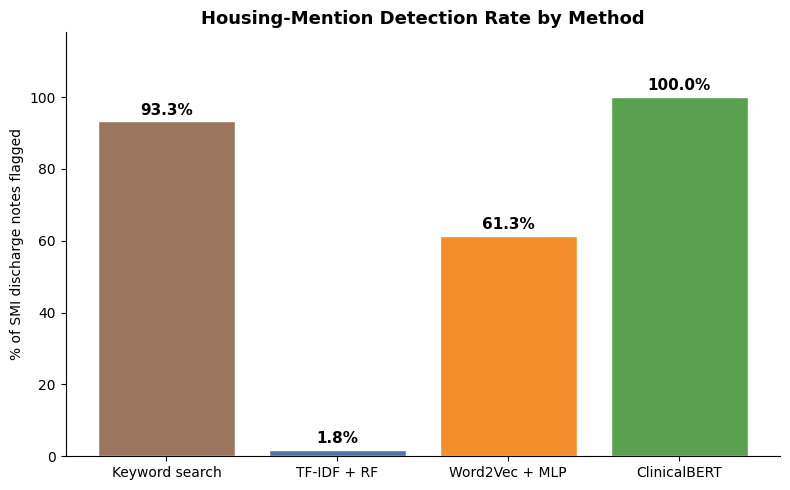

In [65]:
METHODS = [
    ('housing_keyword_pred', 'Keyword search',          '#9c755f'),
    ('housing_rf_pred',      'TF-IDF + RF',             '#4e79a7'),
    ('housing_mlp_pred',     'Word2Vec + MLP',          '#f28e2b'),
    ('housing_bert_pred',    'ClinicalBERT',            '#59a14f'),
]

rates = pd.DataFrame({
    'Method':        [label for _, label, _ in METHODS],
    'Notes flagged': [int(df[col].sum()) for col, _, _ in METHODS],
    '% of cohort':   [df[col].mean() * 100 for col, _, _ in METHODS],
})
print(f"Note-level detection rates on the SMI cohort (n = {len(df):,}):")
display(rates.assign(**{'% of cohort': rates['% of cohort'].map('{:.2f}%'.format)}))

fig, ax = plt.subplots(figsize=(8, 5))
labels  = [label for _, label, _ in METHODS]
values  = [df[col].mean() * 100 for col, _, _ in METHODS]
colors  = [c for _, _, c in METHODS]
bars = ax.bar(labels, values, color=colors, edgecolor='white')
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.1f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('% of SMI discharge notes flagged')
ax.set_title('Housing-Mention Detection Rate by Method', fontsize=13, fontweight='bold')
ax.set_ylim(0, max(values) * 1.18)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## 11. Subgroup Analysis &mdash; Four Methods Side-by-Side

Within each demographic subgroup, what fraction of notes does each of the four methods flag? Where the methods agree we can be more confident the documentation pattern is robust to how we measure it; where they diverge we learn something about each method's biases.

In [66]:
METHOD_COLS = [(col, label, color) for col, label, color in METHODS]

def subgroup_rates_4(df, group_col, level_order):
    rows = []
    for level in level_order:
        sub = df[df[group_col] == level]
        if len(sub) == 0:
            continue
        row = {'group': level, 'n': len(sub)}
        for col, label, _ in METHOD_COLS:
            row[label] = sub[col].mean() * 100
        rows.append(row)
    return pd.DataFrame(rows).set_index('group')


def plot_subgroup_4(rate_df, title):
    levels = list(rate_df.index)
    n_levels = len(levels)
    n_methods = len(METHOD_COLS)
    width = 0.8 / n_methods
    x = np.arange(n_levels)

    fig, ax = plt.subplots(figsize=(max(8, n_levels * 2.0), 4.8))
    for i, (col, label, color) in enumerate(METHOD_COLS):
        bar_x = x + (i - (n_methods - 1) / 2) * width
        bars = ax.bar(bar_x, rate_df[label].values, width,
                      label=label, color=color, edgecolor='white')
        for b, v in zip(bars, rate_df[label].values):
            ax.text(b.get_x() + b.get_width()/2, v + 1.2,
                    f'{v:.0f}%', ha='center', va='bottom', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels([f'{lvl}\n(n={int(rate_df.loc[lvl, "n"]):,})' for lvl in levels],
                       fontsize=10)
    ax.set_ylabel('% of admissions flagged')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylim(0, max(rate_df[[lbl for _, lbl, _ in METHOD_COLS]].values.max() * 1.18, 5))
    ax.legend(loc='upper right', fontsize=9, framealpha=0.9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.show()

### 11.1 By race

,n,Keyword search,TF-IDF + RF,Word2Vec + MLP,ClinicalBERT
group,,,,,
Hispanic,241,95.4,2.5,67.6,100.0
White,2350,93.3,1.8,60.2,100.0
Black,754,95.4,2.1,61.1,100.0
Other,463,88.3,0.6,63.9,100.0


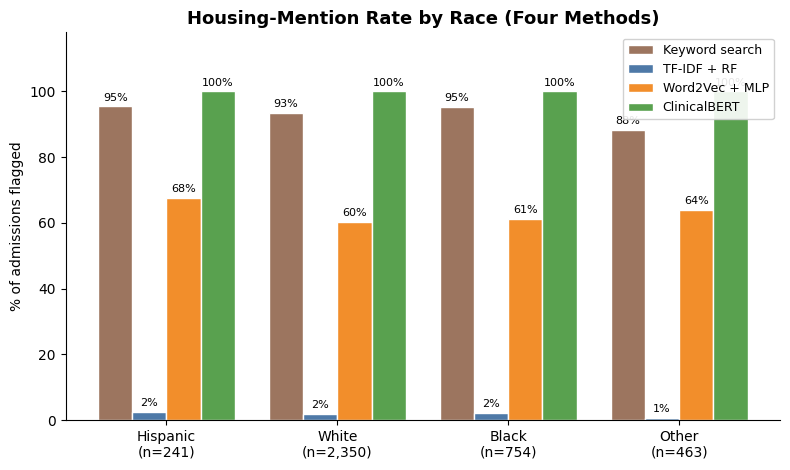

In [67]:
race_rates = subgroup_rates_4(df, 'race_category',
                              ['Hispanic', 'White', 'Black', 'Other'])
display(race_rates.round(1))
plot_subgroup_4(race_rates, 'Housing-Mention Rate by Race (Four Methods)')

### 11.2 By primary diagnosis

,n,Keyword search,TF-IDF + RF,Word2Vec + MLP,ClinicalBERT
group,,,,,
Schizophrenia,1149,95.0,2.1,60.0,100.0
Bipolar Disorder,1195,92.7,1.3,61.7,100.0
Major Depressive\nDisorder,1464,92.3,1.9,62.0,100.0


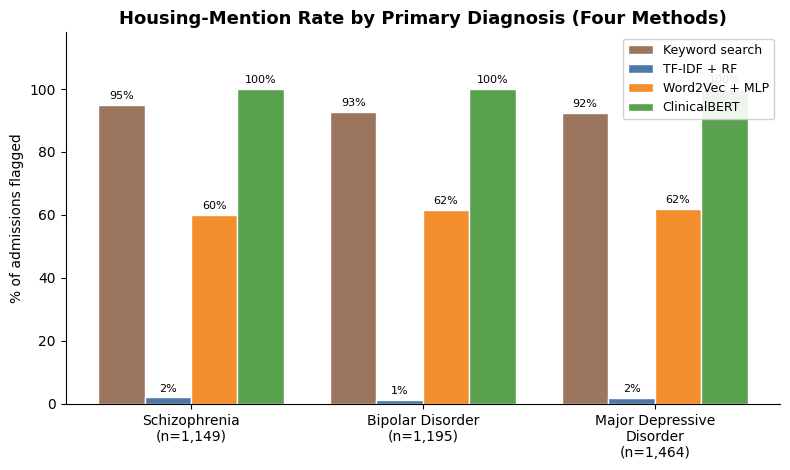

In [68]:
dx_cols = ['schizophrenia', 'bipolar_disorder', 'major_depressive_disorder']
dx_labels = {'schizophrenia': 'Schizophrenia',
             'bipolar_disorder': 'Bipolar Disorder',
             'major_depressive_disorder': 'Major Depressive\nDisorder'}
dx_rows = []
for dx in dx_cols:
    sub = df[df[dx] == 1]
    row = {'group': dx_labels[dx], 'n': len(sub)}
    for col, label, _ in METHOD_COLS:
        row[label] = sub[col].mean() * 100
    dx_rows.append(row)
dx_rates = pd.DataFrame(dx_rows).set_index('group')
display(dx_rates.round(1))
plot_subgroup_4(dx_rates, 'Housing-Mention Rate by Primary Diagnosis (Four Methods)')

### 11.3 By insurance

,n,Keyword search,TF-IDF + RF,Word2Vec + MLP,ClinicalBERT
group,,,,,
Medicaid,836,95.5,2.9,64.8,100.0
Medicare,1369,95.2,2.0,61.0,100.0
Private,1229,89.8,0.7,58.1,100.0
Other,374,92.5,1.9,65.0,100.0


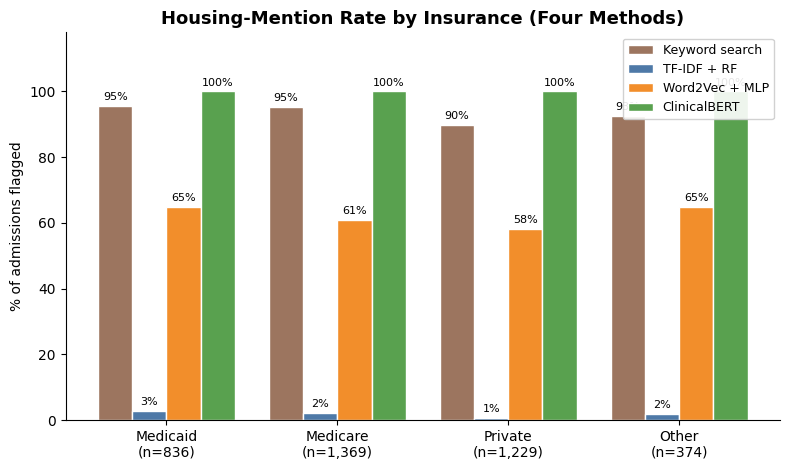

In [69]:
ins_rates = subgroup_rates_4(df, 'insurance_category',
                             ['Medicaid', 'Medicare', 'Private', 'Other'])
display(ins_rates.round(1))
plot_subgroup_4(ins_rates, 'Housing-Mention Rate by Insurance (Four Methods)')

### 11.4 By gender

,n,Keyword search,TF-IDF + RF,Word2Vec + MLP,ClinicalBERT
group,,,,,
F,1941,93.6,1.8,57.7,100.0
M,1867,92.9,1.7,65.1,100.0


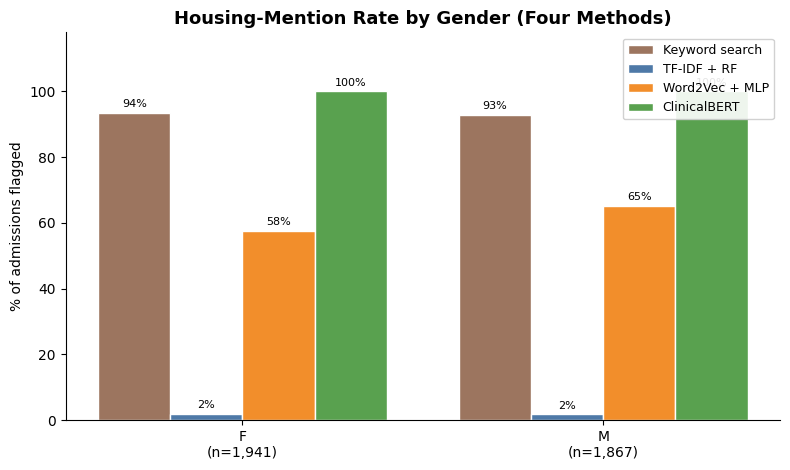

In [70]:
gender_levels = sorted(df['gender'].dropna().unique().tolist())
gender_rates = subgroup_rates_4(df, 'gender', gender_levels)
display(gender_rates.round(1))
plot_subgroup_4(gender_rates, 'Housing-Mention Rate by Gender (Four Methods)')

## 12. Augmented Fine-tuning: ClinicalBERT on Labeled SDOH + Synthetic Sentences

The original fine-tune (§7) used only the 1,800-sentence `MIMIC-III-Labeled-SDOH` dataset. Here we **augment** the training set with two CSVs of synthetic clinical sentences we wrote specifically to match MIMIC-IV phrasing:

- `new_sentences_with_housing_mentions.csv` — 200 housing-positive sentences (group homes, shelters, evictions, transitional housing, etc.).
- `new_sentences_without_housing_mentions.csv` — 100 clearly-not-housing clinical sentences (MSE findings, medication discussions, exam findings, etc.).

The hypothesis is that adding examples written in the same redacted/abbreviation-heavy style as the SMI cohort will close the train-vs-inference distribution gap that hurt our Milestone 3 baselines. The augmented fine-tune is saved to a **separate** Drive path (`clinicalbert_housing_finetuned_augmented`) so the §7 model is untouched, and inference results are cached separately so the two model versions can be compared side-by-side.

### 12.1 Build the augmented training dataset

Load both new CSVs, append them to the original `labeled_sdoh`, shuffle the combined dataframe, then do a fresh 80/20 stratified split.

In [20]:
# Load the two synthetic CSVs (same schema as SyntheticSentences_Round*.csv)
synth_housing  = pd.read_csv(f'{DATA_DIR}/new_sentences_with_housing_mentions.csv')
synth_neg      = pd.read_csv(f'{DATA_DIR}/new_sentences_without_housing_mentions.csv')

print(f"synth_housing:    {len(synth_housing):,} rows  (label counts: "
      f"{synth_housing['label'].value_counts().to_dict()})")
print(f"synth_neg:        {len(synth_neg):,} rows  (label counts: "
      f"{synth_neg['label'].value_counts().to_dict()})")
print(f"labeled_sdoh:     {len(labeled_sdoh):,} rows  (label counts: "
      f"{labeled_sdoh['label'].value_counts().to_dict()})")

# Combine and shuffle
labeled_sdoh_aug = pd.concat(
    [labeled_sdoh[['text', 'label']], synth_housing[['text', 'label']], synth_neg[['text', 'label']]],
    ignore_index=True,
)
labeled_sdoh_aug = labeled_sdoh_aug.dropna(subset=['text', 'label']).copy()
labeled_sdoh_aug['housing_target'] = (
    labeled_sdoh_aug['label'].astype(str).str.strip().str.upper().eq('HOUSING').astype(int)
)

# Shuffle (deterministic via RANDOM_SEED)
labeled_sdoh_aug = labeled_sdoh_aug.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

X_aug = labeled_sdoh_aug['text']
y_aug = labeled_sdoh_aug['housing_target']

print(f"\nAugmented dataset:   {len(labeled_sdoh_aug):,} rows  "
      f"(positive rate: {y_aug.mean()*100:.2f}%)")
print(f"Class counts:\n{y_aug.value_counts().rename({0:'no housing', 1:'housing'})}")

synth_housing:    200 rows  (label counts: {'HOUSING': 200})
synth_neg:        100 rows  (label counts: {'NONE': 100})
labeled_sdoh:     1,800 rows  (label counts: {'EMPLOYMENT': 400, 'RELATIONSHIP': 400, 'SUPPORT': 400, 'HOUSING': 200, 'TRANSPORTATION': 200, 'PARENT': 200})

Augmented dataset:   2,100 rows  (positive rate: 19.05%)
Class counts:
housing_target
no housing    1700
housing        400
Name: count, dtype: int64


In [14]:
X_train_aug, X_val_aug, y_train_aug, y_val_aug = train_test_split(
    X_aug, y_aug,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y_aug,
)
print(f"Augmented training set:   {len(X_train_aug):,} sentences  ({int(y_train_aug.sum())} positive)")
print(f"Augmented validation set: {len(X_val_aug):,} sentences  ({int(y_val_aug.sum())} positive)")

Augmented training set:   1,680 sentences  (320 positive)
Augmented validation set: 420 sentences  (80 positive)


### 12.2 Tokenize and build Hugging Face datasets

In [21]:
# Reuse the §7 tokenizer (it works whether or not the original model was loaded from cache).
SAVE_PATH_AUG = f'{DATA_DIR}/clinicalbert_housing_finetuned_augmented'
ALREADY_TRAINED_AUG = os.path.exists(SAVE_PATH_AUG)

if ALREADY_TRAINED_AUG:
    print(f"Augmented model found at {SAVE_PATH_AUG} — will load instead of retraining.")
    tokenizer_aug = AutoTokenizer.from_pretrained(SAVE_PATH_AUG)
else:
    print("No augmented model found — will fine-tune from scratch.")
    tokenizer_aug = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_batch_aug(batch):
    return tokenizer_aug(batch['text'], truncation=True, max_length=MAX_LENGTH)

train_df_aug = pd.DataFrame({'text': X_train_aug.values, 'labels': y_train_aug.values})
val_df_aug   = pd.DataFrame({'text': X_val_aug.values,   'labels': y_val_aug.values})

train_ds_aug = Dataset.from_pandas(train_df_aug, preserve_index=False)
val_ds_aug   = Dataset.from_pandas(val_df_aug,   preserve_index=False)

train_ds_aug = train_ds_aug.map(tokenize_batch_aug, batched=True, remove_columns=['text'])
val_ds_aug   = val_ds_aug.map(tokenize_batch_aug,   batched=True, remove_columns=['text'])

print(train_ds_aug)
print(val_ds_aug)

Augmented model found at drive/MyDrive/AC209b-project-data/clinicalbert_housing_finetuned_augmented — will load instead of retraining.


Map:   0%|          | 0/1680 [00:00<?, ? examples/s]

Map:   0%|          | 0/420 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1680
})
Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 420
})


### 12.3 Fine-tune ClinicalBERT on the augmented dataset

Same hyperparameters as §7 (lr=2e-5, 3 epochs, batch=16, warmup_ratio=0.1, class-weighted loss). We reuse the `WeightedLossTrainer` class and `compute_metrics` function defined in §7.3 — only the model, args, datasets, and class weights change.

In [22]:
class_weight_array_aug = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=y_train_aug.values,
)
class_weights_aug_t = torch.tensor(class_weight_array_aug, dtype=torch.float)
print(f"Augmented class weights (neg, pos): {class_weight_array_aug}")

if ALREADY_TRAINED_AUG:
    bert_model_aug = AutoModelForSequenceClassification.from_pretrained(SAVE_PATH_AUG, num_labels=2)
    print("Loaded augmented fine-tuned model from Drive.")
    trainer_aug = None
else:
    bert_model_aug = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    OUTPUT_DIR_AUG = 'clinicalbert_housing_run_augmented'

    training_args_aug = TrainingArguments(
        output_dir=OUTPUT_DIR_AUG,
        num_train_epochs=3,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        greater_is_better=True,
        save_total_limit=1,
        seed=RANDOM_SEED,
        report_to='none',
    )

    data_collator_aug = DataCollatorWithPadding(tokenizer=tokenizer_aug)

    trainer_aug = WeightedLossTrainer(
        model=bert_model_aug,
        args=training_args_aug,
        train_dataset=train_ds_aug,
        eval_dataset=val_ds_aug,
        processing_class=tokenizer_aug,
        data_collator=data_collator_aug,
        compute_metrics=compute_metrics,
        class_weights=class_weights_aug_t,
    )

Augmented class weights (neg, pos): [0.61764706 2.625     ]


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loaded augmented fine-tuned model from Drive.


In [23]:
if ALREADY_TRAINED_AUG:
    print("Skipping fine-tuning — augmented model already loaded from Drive.")
else:
    train_result_aug = trainer_aug.train()
    print(train_result_aug)

Skipping fine-tuning — augmented model already loaded from Drive.


### 12.4 Save augmented model to Drive

In [24]:
if not ALREADY_TRAINED_AUG:
    os.makedirs(SAVE_PATH_AUG, exist_ok=True)
    trainer_aug.save_model(SAVE_PATH_AUG)
    tokenizer_aug.save_pretrained(SAVE_PATH_AUG)
    print(f"Augmented model and tokenizer saved to {SAVE_PATH_AUG}")
else:
    print("Augmented model was loaded from Drive — no save needed.")

Augmented model was loaded from Drive — no save needed.


### 12.5 Threshold tuning on augmented validation

Loaded saved augmented threshold: 0.033
Default 0.50 -> F1 = 0.940
Tuned 0.033 -> F1 = 0.975  (precision 0.975, recall 0.975)

--- Augmented ClinicalBERT validation report @ tuned threshold ---

              precision    recall  f1-score   support

  No Housing       0.99      0.99      0.99       340
     Housing       0.97      0.96      0.97        80

    accuracy                           0.99       420
   macro avg       0.98      0.98      0.98       420
weighted avg       0.99      0.99      0.99       420



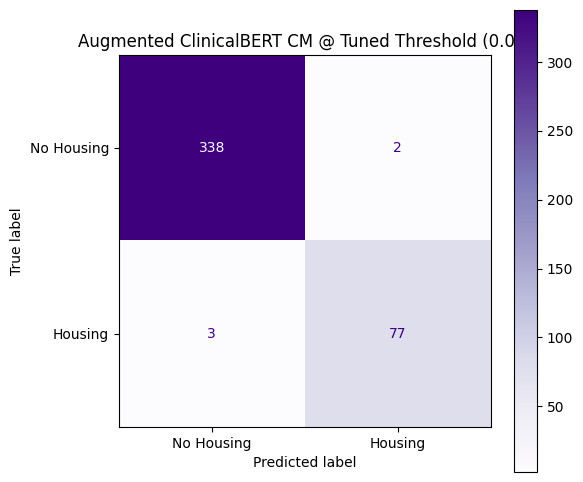

In [25]:
from torch.utils.data import DataLoader

THRESHOLD_PATH_AUG = f'{SAVE_PATH_AUG}/best_threshold.json'

if os.path.exists(THRESHOLD_PATH_AUG):
    with open(THRESHOLD_PATH_AUG) as _f:
        best_threshold_bert_aug = json.load(_f)['best_threshold']
    print(f"Loaded saved augmented threshold: {best_threshold_bert_aug:.3f}")
    if trainer_aug is not None:
        val_pred_output_aug = trainer_aug.predict(val_ds_aug)
        val_logits_aug = val_pred_output_aug.predictions
    else:
        bert_model_aug.eval()
        bert_model_aug.to(device)
        loader_aug = DataLoader(val_ds_aug, batch_size=32,
                                 collate_fn=DataCollatorWithPadding(tokenizer_aug))
        all_logits = []
        with torch.no_grad():
            for batch in loader_aug:
                batch = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
                all_logits.append(bert_model_aug(**batch).logits.cpu())
        val_logits_aug = torch.cat(all_logits).numpy()
    val_proba_bert_aug = torch.softmax(torch.tensor(val_logits_aug), dim=-1)[:, 1].numpy()
    y_val_arr_aug = np.asarray(y_val_aug)
    precisions_aug, recalls_aug, thresholds_aug = precision_recall_curve(y_val_arr_aug, val_proba_bert_aug)
    f1s_aug = 2 * precisions_aug[:-1] * recalls_aug[:-1] / (precisions_aug[:-1] + recalls_aug[:-1] + 1e-10)
    best_idx_bert_aug = int(np.argmax(f1s_aug))
else:
    val_pred_output_aug = trainer_aug.predict(val_ds_aug)
    val_logits_aug = val_pred_output_aug.predictions
    val_proba_bert_aug = torch.softmax(torch.tensor(val_logits_aug), dim=-1)[:, 1].numpy()
    y_val_arr_aug = np.asarray(y_val_aug)
    precisions_aug, recalls_aug, thresholds_aug = precision_recall_curve(y_val_arr_aug, val_proba_bert_aug)
    f1s_aug = 2 * precisions_aug[:-1] * recalls_aug[:-1] / (precisions_aug[:-1] + recalls_aug[:-1] + 1e-10)
    best_idx_bert_aug = int(np.argmax(f1s_aug))
    best_threshold_bert_aug = float(thresholds_aug[best_idx_bert_aug])
    with open(THRESHOLD_PATH_AUG, 'w') as _f:
        json.dump({'best_threshold': best_threshold_bert_aug}, _f)
    print(f"Augmented threshold saved to {THRESHOLD_PATH_AUG}")

default_pred_aug = (val_proba_bert_aug >= 0.5).astype(int)
tuned_pred_aug   = (val_proba_bert_aug >= best_threshold_bert_aug).astype(int)

print(f"Default 0.50 -> F1 = {f1_score(y_val_arr_aug, default_pred_aug):.3f}")
print(f"Tuned {best_threshold_bert_aug:.3f} -> F1 = {f1s_aug[best_idx_bert_aug]:.3f}  "
      f"(precision {precisions_aug[best_idx_bert_aug]:.3f}, recall {recalls_aug[best_idx_bert_aug]:.3f})")
print()
print('--- Augmented ClinicalBERT validation report @ tuned threshold ---\n')
print(classification_report(y_val_arr_aug, tuned_pred_aug, target_names=['No Housing', 'Housing']))

cm_bert_aug = confusion_matrix(y_val_arr_aug, tuned_pred_aug)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_bert_aug, display_labels=['No Housing', 'Housing'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap='Purples')
plt.title(f'Augmented ClinicalBERT CM @ Tuned Threshold ({best_threshold_bert_aug:.2f})')
plt.show()

### 12.6 Apply augmented ClinicalBERT to the SMI cohort (cached)

Same as §8.3 but writing to a separate predictions CSV so the original BERT cache is untouched.

In [29]:
PREDS_BERT_AUG_PATH = f'{DATA_DIR}/smi_sentences_filtered_bert_preds_augmented.csv'

if os.path.exists(PREDS_BERT_AUG_PATH):
    print(f"Loading saved augmented BERT predictions from {PREDS_BERT_AUG_PATH}...")
    bert_preds_aug_df = pd.read_csv(PREDS_BERT_AUG_PATH)
    smi_sentences_filtered = smi_sentences_filtered.merge(
        bert_preds_aug_df[['hadm_id', 'sentence_text',
                           'housing_bert_proba_aug', 'housing_bert_pred_aug']],
        on=['hadm_id', 'sentence_text'], how='left',
    )
    n_loaded = smi_sentences_filtered['housing_bert_pred_aug'].notna().sum()
    print(f"Merged augmented BERT predictions for {n_loaded:,} / "
          f"{len(smi_sentences_filtered):,} sentences.")
else:
    smi_sentences_filtered['housing_bert_proba_aug'] = bert_predict_proba(
        smi_sentences_filtered['sentence_text'], bert_model_aug, tokenizer_aug, device
    )
    smi_sentences_filtered['housing_bert_pred_aug'] = (
        smi_sentences_filtered['housing_bert_proba_aug'] >= best_threshold_bert_aug
    ).astype(int)
    smi_sentences_filtered[['hadm_id', 'sentence_text',
                            'housing_bert_proba_aug', 'housing_bert_pred_aug']].to_csv(
        PREDS_BERT_AUG_PATH, index=False
    )
    print(f"Augmented predictions saved to {PREDS_BERT_AUG_PATH}")

smi_sentences_filtered['housing_bert_pred_aug'] = (
    smi_sentences_filtered['housing_bert_pred_aug'].fillna(0).astype(int)
)

# Aggregate to admission level
note_preds_bert_aug = (
    smi_sentences_filtered.groupby('hadm_id')['housing_bert_pred_aug']
    .max().reset_index()
)
df = df.drop(columns=['housing_bert_pred_aug'], errors='ignore').merge(
    note_preds_bert_aug, on='hadm_id', how='left'
)
df['housing_bert_pred_aug'] = df['housing_bert_pred_aug'].fillna(0).astype(int)

n_aug = int(df['housing_bert_pred_aug'].sum())
print(f"Augmented ClinicalBERT flagged {n_aug:,} / {len(df):,} notes "
      f"({n_aug/len(df)*100:.2f}%)")

BERT inference:   0%|          | 0/3534 [00:00<?, ?it/s]

KeyboardInterrupt: 

### 12.7 Compare original vs. augmented ClinicalBERT

Side-by-side detection rates at the sentence and note levels, plus the breakdown of where the two models disagree on the SMI cohort.

In [ ]:
# Sentence-level comparison
n_total = len(smi_sentences_filtered)
n_pos_orig = int(smi_sentences_filtered['housing_bert_pred'].sum())
n_pos_aug  = int(smi_sentences_filtered['housing_bert_pred_aug'].sum())
n_agree    = int((smi_sentences_filtered['housing_bert_pred']
                  == smi_sentences_filtered['housing_bert_pred_aug']).sum())

print(f"Sentence-level (n = {n_total:,}):")
print(f"  Original ClinicalBERT positive:  {n_pos_orig:,} ({n_pos_orig/n_total*100:.2f}%)")
print(f"  Augmented ClinicalBERT positive: {n_pos_aug:,} ({n_pos_aug/n_total*100:.2f}%)")
print(f"  Agreement (same prediction):     {n_agree:,} ({n_agree/n_total*100:.2f}%)")
print()

# Disagreement breakdown
both_pos   = ((smi_sentences_filtered['housing_bert_pred'] == 1) &
              (smi_sentences_filtered['housing_bert_pred_aug'] == 1)).sum()
orig_only  = ((smi_sentences_filtered['housing_bert_pred'] == 1) &
              (smi_sentences_filtered['housing_bert_pred_aug'] == 0)).sum()
aug_only   = ((smi_sentences_filtered['housing_bert_pred'] == 0) &
              (smi_sentences_filtered['housing_bert_pred_aug'] == 1)).sum()
both_neg   = ((smi_sentences_filtered['housing_bert_pred'] == 0) &
              (smi_sentences_filtered['housing_bert_pred_aug'] == 0)).sum()

print(f"  Both POSITIVE:        {both_pos:,}")
print(f"  Original only POS:    {orig_only:,}  (augmented flipped to NEG)")
print(f"  Augmented only POS:   {aug_only:,}  (augmentation added positive)")
print(f"  Both NEGATIVE:        {both_neg:,}")

# Note-level
n_notes_orig = int(df['housing_bert_pred'].sum())
n_notes_aug  = int(df['housing_bert_pred_aug'].sum())
print()
print(f"Note-level (n = {len(df):,}):")
print(f"  Original ClinicalBERT flagged notes:  {n_notes_orig:,} ({n_notes_orig/len(df)*100:.2f}%)")
print(f"  Augmented ClinicalBERT flagged notes: {n_notes_aug:,} ({n_notes_aug/len(df)*100:.2f}%)")

# Bar plot of the two
fig, ax = plt.subplots(figsize=(7, 4.5))
labels = ['ClinicalBERT (original)', 'ClinicalBERT (augmented)']
values = [n_notes_orig / len(df) * 100, n_notes_aug / len(df) * 100]
bars = ax.bar(labels, values, color=['#59a14f', '#76b7b2'], edgecolor='white')
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.1f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('% of SMI discharge notes flagged')
ax.set_title('Housing-Mention Detection: Original vs. Augmented ClinicalBERT',
             fontsize=12, fontweight='bold')
ax.set_ylim(0, max(values) * 1.18)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

# Show 10 random sentences where the two models disagree
disagree = smi_sentences_filtered[
    smi_sentences_filtered['housing_bert_pred'] != smi_sentences_filtered['housing_bert_pred_aug']
]
if len(disagree) > 0:
    print()
    print('='*70)
    print('10 random sentences where Original BERT and Augmented BERT DISAGREE')
    print('='*70)
    sample = disagree.sample(min(10, len(disagree)), random_state=RANDOM_SEED)
    for _, r in sample.iterrows():
        txt = r['sentence_text']
        if len(txt) > 200:
            txt = txt[:200] + '...'
        print(f"  [hadm {r['hadm_id']}]")
        print(f"    orig:  P={r['housing_bert_proba']:.3f} -> pred {int(r['housing_bert_pred'])}")
        print(f"    aug:   P={r['housing_bert_proba_aug']:.3f} -> pred {int(r['housing_bert_pred_aug'])}")
        print(f"    text:  {txt}")
        print()

## 13. Summary

This notebook implements the full Final Model Pipeline laid out at the end of Milestone 3:

1. **Keyword search baseline** &mdash; evaluated on the labeled SDOH dataset (precision/recall/F1 + confusion matrix), applied to the SMI cohort, and broken down by demographic subgroup.
2. **Length analysis** &mdash; documented the ~100x length gap between SMI discharge notes and labeled SDOH sentences, motivating the sentence-level inference pipeline.
3. **TF-IDF + Random Forest** &mdash; trained on the labeled SDOH split with `class_weight='balanced'` and a small grid search.
4. **Word2Vec + MLP** &mdash; custom 100-dim embeddings trained on SMI sentences, mean-pooled, fed to a 2-layer MLP, threshold F1-tuned on validation.
5. **Bio_ClinicalBERT** &mdash; fine-tuned on the labeled SDOH split with a class-weighted loss, threshold F1-tuned on validation, model + threshold cached to Drive.
6. **Inference on the SMI cohort** &mdash; all four methods applied at the sentence level (where applicable) and aggregated to admission-level housing flags.
7. **Comparison + subgroup breakdowns** &mdash; overall detection rate by method, and rates broken down by race, primary diagnosis, insurance, and gender.

The §11 subgroup plots are the headline output: putting all four methods side-by-side shows where contextual modeling expands or contracts the picture of housing documentation that the keyword search alone produced.